<a href="https://colab.research.google.com/github/beingham/Doit_R/blob/master/stablecoin_master_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 스테이블코인 준비금 공시의 시장반응 분석
## 분석 코드 제출본 | stablecoin_master_v7.ipynb
---

| 항목 | 내용 |
|---|---|
| **논문 제목** | 스테이블코인 준비금 공시의 시장반응 분석 |
| **분석 대상** | USDT(17건) · USDC(5건) — 총 22개 이벤트 (공개일 기준, 2021-05 ~ 2025-01) |
| **주 분석 창** | CAR(−5,+5) — 잔차 정규성 유일 통과 (SW p=0.625) |
| **시장 지수** | 비트코인(BTC) 일별 로그수익률 |
| **실행 환경** | Google Colab (Python 3.x) |
| **H2 표준오차** | 이벤트 날짜 군집(G=22) + wild cluster restricted bootstrap (Webb, 9,999회) |
| **v9 변경 (2026-10)** | 이벤트일을 실제 공개일로 재구축(분기말 기준일 → 발표일), CFTC 일자 정정(2021-10-15), 중복 이벤트 제거 |
| **v8 변경 (2026-10)** | 횡단면 회귀의 HAC·DW 기반 SE 선택 → 날짜 군집 SE로 교체 · 데이터 스냅샷 옵션 · STEP 9-1 추가 강건성 · STEP 10-1 거래량 채널/공시 한정 H2 · H3 N=1 라벨 수정 |

---

### ▶ 실행 순서

STEP 0 → STEP 1 → … → STEP 13 순서대로 **순차 실행**합니다.  
STEP 0의 Google Drive 마운트를 먼저 완료한 뒤 나머지 셀을 실행하세요.


---


---
## STEP 0 | 환경 설정

> 라이브러리 설치·임포트, 전역 파라미터(EST_WIN·EVT_WIN·PRIMARY_WIN 등), HAC maxlags 동적 함수, 오염 이벤트 제거 목록 정의.


In [1]:
# ▼ Google Colab 실행 시 아래 두 줄 주석 해제
# from google.colab import drive
# drive.mount('/content/drive')

import os
BASE = ('/content/drive/MyDrive/stablecoin_research' if os.path.exists('/content/drive')
        else './stablecoin_research')   # Colab 외 환경에서도 실행 가능
DIRS = {k: f'{BASE}/{k}' for k in
        ['raw','events','processed','results','tables','figures','validation']}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

!pip install yfinance statsmodels scipy -q

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import (shapiro, jarque_bera, mannwhitneyu,
                         ttest_1samp, ttest_ind)
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
import yfinance as yf
warnings.filterwarnings('ignore')

!apt-get install -y fonts-nanum -qq > /dev/null
import matplotlib.font_manager as fm
_NANUM = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(_NANUM):
    fm.fontManager.ttflist.insert(0, fm.FontEntry(fname=_NANUM, name='NanumGothic'))
    plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams.update({'axes.unicode_minus':False,
                     'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})

# ── 전역 파라미터
START_COLLECT = '2020-07-01'
END_DATE      = '2025-04-30'
EST_WIN       = (-250, -11)
EVT_WIN       = (-10,  +10)
MIN_OBS       = 50
N_BOOT        = 5000
SEED          = 42
PRIMARY_WIN   = 'CAR_-5_5'
N_WBOOT       = 9999     # wild cluster bootstrap 반복 수 (H2)
USE_SNAPSHOT  = True     # True: 논문 수치 재현용 가격 스냅샷(master_daily.csv) 사용 / False: yfinance 새로 수집
SNAPSHOT_URL  = 'https://raw.githubusercontent.com/beingham/stablecoin/main/master_daily.csv'
ALL_WINS      = ['CAR_-1_1', 'CAR_-3_3', 'CAR_-5_5']
np.random.seed(SEED)

# ──  HAC maxlags 동적 계산 함수 (시장모형 시계열 추정에만 사용)
def get_maxlags(n):
    """소표본 수치 불안정 방지: N//3 기반 동적 제한, 최소 1 최대 5"""
    return min(5, max(1, int(n) // 3))

# ── 제거된 오염 이벤트 (분석 미포함, 투명성 기록용)
EXCLUDED_EVENTS = [
    {'coin':'USDT','date':'2021-10-07','reason':'Bloomberg 보도 — CFTC(2021-10-15)와 이벤트창 중첩'},
    {'coin':'USDT','date':'2022-11-10','reason':'Q3 2022 증명 공개 — FTX 파산(2022-11-11)과 1일 차'},
    {'coin':'USDC','date':'2022-11-03','reason':'Circle Reserve Fund 발표 — FTX 파산과 8일 차'},
    {'coin':'USDC','date':'2023-03-13','reason':'페그 회복 — SVB(2023-03-10)와 이벤트창 중첩'},
]
pd.DataFrame(EXCLUDED_EVENTS).to_csv(
    f"{DIRS['validation']}/excluded_events.csv", index=False, encoding='utf-8-sig')

print('✅ 환경 설정 완료')
print(f'   주 분석 창: {PRIMARY_WIN}')
print(f'   시장모형 SE: HAC 동적 maxlags (N//3, 최소 1 최대 5)')
print(f'   H2 횡단면 SE: 이벤트 날짜 군집 + wild cluster bootstrap({N_WBOOT}회)')
print(f'   데이터: {"스냅샷 " + SNAPSHOT_URL if USE_SNAPSHOT else "yfinance 신규 수집"}')
print(f'   제거 이벤트: {[(e["coin"],e["date"]) for e in EXCLUDED_EVENTS]}')


✅ 환경 설정 완료
   주 분석 창: CAR_-5_5
   시장모형 SE: HAC 동적 maxlags (N//3, 최소 1 최대 5)
   H2 횡단면 SE: 이벤트 날짜 군집 + wild cluster bootstrap(9999회)
   데이터: 스냅샷 https://raw.githubusercontent.com/beingham/stablecoin/main/master_daily.csv
   제거 이벤트: [('USDT', '2021-10-07'), ('USDT', '2022-11-10'), ('USDC', '2022-11-03'), ('USDC', '2023-03-13')]


---
## STEP 1 | 데이터 수집

> yfinance로 USDT·USDC·BTC 일별 가격·거래량 수집. 로그수익률, 패그이탈(|price−1|), 거래량 변화율 계산.


In [2]:
TICKERS = {'USDT-USD':'USDT', 'USDC-USD':'USDC', 'BTC-USD':'BTC'}
raw_dfs = {}

if USE_SNAPSHOT:
    # Yahoo Finance 과거 데이터는 사후 수정될 수 있으므로, 논문 수치는 고정 스냅샷으로 재현한다.
    snap = pd.read_csv(SNAPSHOT_URL, parse_dates=['date'])
    for sym in ['USDT', 'USDC']:
        k = sym.lower()
        df = snap[['date', f'p_{k}', f'v_{k}', f'r_{k}', f'dev_{k}', f'vc_{k}']].rename(columns={
            f'p_{k}':'price', f'v_{k}':'volume', f'r_{k}':'log_return', f'dev_{k}':'price_dev', f'vc_{k}':'vol_chg'})
        df['coin'] = sym
        raw_dfs[sym] = df
    raw_dfs['BTC'] = snap[['date','r_btc']].rename(columns={'r_btc':'log_return'}).assign(
        price=np.nan, volume=np.nan, coin='BTC')
    raw_dfs['BTC']['price'] = 1.0   # 스냅샷에는 BTC 가격 수준이 없음(수익률만 사용) — 검증 셀의 결측 판정용 자리값
    for sym, df in raw_dfs.items():
        df.to_csv(f"{DIRS['raw']}/{sym}.csv", index=False)
        print(f'   ✅ {sym} (스냅샷): {len(df)}일  ({df.date.min().date()} ~ {df.date.max().date()})')

for ticker, sym in (TICKERS.items() if not USE_SNAPSHOT else []):
    print(f'🔄 {sym}...')
    df = yf.download(ticker, start=START_COLLECT, end=END_DATE,
                     interval='1d', auto_adjust=True, progress=False)
    df = df.reset_index()
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = ['_'.join([c for c in col if c]).strip('_') for col in df.columns]
    df.columns = [c.lower() for c in df.columns]
    close_col  = next(c for c in df.columns if 'close'  in c)
    volume_col = next(c for c in df.columns if 'volume' in c)
    date_col   = next(c for c in df.columns if 'date'   in c)
    df = df.rename(columns={date_col:'date', close_col:'price', volume_col:'volume'})
    df = df[['date','price','volume']].copy()
    df['date']       = pd.to_datetime(df['date']).dt.normalize()
    df               = df.dropna(subset=['price']).sort_values('date').reset_index(drop=True)
    df['coin']       = sym
    df['log_return'] = np.log(df['price'] / df['price'].shift(1))
    df['price_dev']  = (df['price'] - 1.0).abs()
    df['vol_chg']    = np.log(df['volume'] / df['volume'].shift(1))
    df.to_csv(f"{DIRS['raw']}/{sym}.csv", index=False)
    raw_dfs[sym] = df
    print(f'   ✅ {sym}: {len(df)}일  ({df.date.min().date()} ~ {df.date.max().date()})')
    time.sleep(1)


   ✅ USDT (스냅샷): 1764일  (2020-07-01 ~ 2025-04-29)
   ✅ USDC (스냅샷): 1764일  (2020-07-01 ~ 2025-04-29)
   ✅ BTC (스냅샷): 1764일  (2020-07-01 ~ 2025-04-29)


---
## STEP 2 | 이벤트 정의 (22건, 실제 공개일 기준)

> 공시 품질지수 `score()` (1~5점). 이벤트일은 보고서 기준일이 아니라 시장에 공개된 날. 각 이벤트에 1차 자료/보도 URL 기록.


In [3]:
def score(amt=True, composition=False, detail=False, audit=False):
    """공시 품질 지수 1~5점 (인자명 명확화)
    ①amt: 준비금 총액 공시  ②composition: 자산 구성 공시
    ③detail: 세부 발행사/만기  ④audit: 제3자 독립 감사
    반환: 충족 기준 수 + 1  →  1점(모두 미충족) ~ 5점(모두 충족)
    """
    return int(amt) + int(composition) + int(detail) + int(audit) + 1

# ── 최종 이벤트 목록 (v9: 실제 공개일 기준으로 전면 재구축)
#   이벤트일 = 정보가 시장에 처음 공개된 날(보고서·보도자료 발표일). 보고서 기준일(분기말)이 아님.
#   품질지수 코딩 규칙(공시 내용만으로 판정, CAR 산출 전 고정):
#     ① amt: 준비금 총액 공개  ② composition: 자산군별 구성 공개
#     ③ detail: 자산군 이하 세부(신용등급·만기·발행사·CUSIP·보관기관 중 하나 이상)
#     ④ audit: 독립 회계법인이 '구성 내역까지' 확인한 증명(attestation)
#   유형: negative = 제재·준비금 손상·시장 전체 위기 / positive = 직전 공시 대비 투명성 확대 또는 위험자산 축소 /
#         neutral = 실질 변화 없는 정기 공시
#   제외(분석 미포함): USDT 2021-10-07 Bloomberg 보도(CFTC 10-15와 창 중첩), USDT 2022-11-10 Q3'22 증명(FTX 11-11과 1일 차),
#         USDC 2022-11-03 Circle Reserve Fund 발표(FTX와 8일 차), USDC 2023-03-13 페그 회복(SVB와 창 중첩),
#         NYAG 합의 2021-02-23(추정창 부족). 2022-11 이후 USDC 월간 증명은 준비금 펀드 보유내역이
#         매일 공개되므로 새 정보 이벤트로 보지 않음.
T = 'https://tether.io/news/'
events_raw = [
    # ── USDT (17건)
    dict(coin='USDT', event_date='2021-05-13', event_type='positive', quality_score=score(True,True,False,False),
         description='First reserve breakdown (as of 2021-03-31); composition unattested; CP 49%',
         source='The Block / CoinDesk 2021-05-13', source_url='https://www.theblock.co/post/104780/tether-usdt-reserves-breakdown-first-time-since-launch'),
    dict(coin='USDT', event_date='2021-08-09', event_type='positive', quality_score=score(True,True,True,True),
         description='Q2 2021 attestation: CP ratings and maturity buckets disclosed',
         source='CoinDesk 2021-08-09', source_url='https://www.coindesk.com/markets/2021/08/09/tether-reveals-more-details-about-its-reserves'),
    dict(coin='USDT', event_date='2021-10-15', event_type='negative', quality_score=score(False,False,False,False),
         description='CFTC order: USD 41M civil penalty for reserve misrepresentation',
         source='CFTC Press Release 8450-21', source_url='https://www.cftc.gov/PressRoom/PressReleases/8450-21'),
    dict(coin='USDT', event_date='2021-12-03', event_type='neutral', quality_score=score(True,True,True,True),
         description='Q3 2021 attestation (as of 2021-09-30)',
         source='Tether 2021-12-03', source_url=T+'assurance-opinion-re-affirms-tethers-reserves-fully-backed/'),
    dict(coin='USDT', event_date='2022-02-21', event_type='positive', quality_score=score(True,True,True,True),
         description='Q4 2021 attestation: CP cut 21%',
         source='Tether 2022-02-21', source_url=T+'tether-latest-assurance-opinion-reveals-reserves-held-exceeds-liabilities/'),
    dict(coin='USDT', event_date='2022-05-19', event_type='positive', quality_score=score(True,True,True,True),
         description='Q1 2022 attestation: CP cut 17%',
         source='CoinDesk 2022-05-19', source_url='https://www.coindesk.com/business/2022/05/19/tether-cut-commercial-paper-reserve-by-17-in-q1'),
    dict(coin='USDT', event_date='2022-08-19', event_type='positive', quality_score=score(True,True,True,True),
         description='Q2 2022 attestation, first by BDO Italia: CP cut 58%',
         source='Tether 2022-08-19', source_url=T+'tether-releases-independent-auditor-report-from-top-5-accounting-firm-bdo-reinforcing-its-dedication-to-transparency-and-revealing-another-major-cut-to-commercial-paper-holdings/'),
    dict(coin='USDT', event_date='2022-11-11', event_type='negative', quality_score=score(False,False,False,False),
         description='FTX Chapter 11 filing: market-wide stress, brief USDT discount',
         source='FTX bankruptcy filing (Kroll)', source_url='https://cases.ra.kroll.com/FTX/'),
    dict(coin='USDT', event_date='2023-02-09', event_type='positive', quality_score=score(True,True,True,True),
         description='Q4 2022 attestation: CP eliminated, USD 700M profit',
         source='CoinDesk 2023-02-09', source_url='https://www.coindesk.com/business/2023/02/09/stablecoin-issuer-tether-reports-700m-profit-for-q4-2022'),
    dict(coin='USDT', event_date='2023-05-10', event_type='positive', quality_score=score(True,True,True,True),
         description='Q1 2023 attestation (BDO): USD 1.48B profit, excess reserves',
         source='The Block 2023-05-10', source_url='https://www.theblock.co/post/230241/tether-attestation-report-q1-2023'),
    dict(coin='USDT', event_date='2023-07-31', event_type='positive', quality_score=score(True,True,True,True),
         description='Q2 2023 attestation: USD 850M profit, T-bill exposure 72B',
         source='The Block 2023-07-31', source_url='https://www.theblock.co/post/242205/tether-q2-2023-attestation'),
    dict(coin='USDT', event_date='2023-10-31', event_type='neutral', quality_score=score(True,True,True,True),
         description='Q3 2023 attestation: excess reserves 3.2B',
         source='Cryptonews 2023-11-01', source_url='https://cryptonews.com/news/tethers-q3-attestation-reveals-3-2-billion-excess-reserves-backing-usdt/'),
    dict(coin='USDT', event_date='2024-01-31', event_type='positive', quality_score=score(True,True,True,True),
         description='Q4 2023 attestation: record quarterly profit 2.85B',
         source='Benzinga 2024-01-31', source_url='https://www.benzinga.com/markets/cryptocurrency/24/01/36874907/tether-books-2-85b-quarterly-profit-we-look-forward-to-great-2024-says-ceo-paolo-ardoino'),
    dict(coin='USDT', event_date='2024-05-01', event_type='positive', quality_score=score(True,True,True,True),
         description='Q1 2024 attestation: profit 4.52B, group equity disclosed',
         source='The Block 2024-05-01', source_url='https://www.theblock.co/post/291938/tether-sees-record-net-profit-of-over-4-5-billion-in-first-quarter-of-2024'),
    dict(coin='USDT', event_date='2024-07-31', event_type='positive', quality_score=score(True,True,True,True),
         description='Q2 2024 attestation: H1 profit 5.2B',
         source='The Block 2024-07-31', source_url='https://www.theblock.co/post/308599/tether-generates-a-record-5-2-billion-profit-in-first-half-of-the-year'),
    dict(coin='USDT', event_date='2024-10-31', event_type='neutral', quality_score=score(True,True,True,True),
         description='Q3 2024 attestation',
         source='The Block 2024-10-31', source_url='https://www.theblock.co/post/324075/tether-registers-2-5-billion-in-net-profit-for-q3-bringing-year-to-date-total-to-7-7-billion'),
    dict(coin='USDT', event_date='2025-01-31', event_type='positive', quality_score=score(True,True,True,True),
         description='Q4 2024 attestation: 2024 profit 13B, record T-bill holdings',
         source='The Block 2025-01-31', source_url='https://www.theblock.co/post/338275/tether-reports-13-billion-in-yearly-net-profits-for-2024'),
    # ── USDC (5건)
    dict(coin='USDC', event_date='2021-07-20', event_type='positive', quality_score=score(True,True,False,True),
         description='First USDC reserve breakdown in Grant Thornton attestation (61% cash, CP/Yankee CDs)',
         source='Circle blog 2021-07-20', source_url='https://www.circle.com/blog/greater-transparency-for-usdc-reserves'),
    dict(coin='USDC', event_date='2021-08-23', event_type='positive', quality_score=score(False,True,False,False),
         description='Reserves to move to 100% cash and short-duration U.S. Treasuries',
         source='Circle blog / ForkLog 2021-08-23', source_url='https://www.circle.com/blog/evolving-usdc-reserves-to-100-cash-and-short-duration-us-treasuries'),
    dict(coin='USDC', event_date='2022-12-23', event_type='positive', quality_score=score(True,True,True,True),
         description='Attestation adds CUSIP-level T-bill holdings, maturities and custodian banks',
         source='Circle blog 2022-12-23', source_url='https://www.circle.com/blog/circle-continues-to-enhance-details-in-the-usdc-reserve-attestations'),
    dict(coin='USDC', event_date='2023-01-17', event_type='positive', quality_score=score(False,False,False,True),
         description='Circle appoints Deloitte (Big Four) for reserve assurance',
         source='Blockworks 2023-01-17', source_url='https://blockworks.com/news/circle-taps-deloitte-as-new-auditor-doubles-down-on-proof-of-reserves'),
    dict(coin='USDC', event_date='2023-03-10', event_type='negative', quality_score=score(False,False,False,False),
         description='SVB failure; Circle discloses USD 3.3B of reserves held at SVB',
         source='FDIC PR-16-2023; Circle 2023-03-10', source_url='https://www.fdic.gov/news/press-releases/2023/pr23016.html'),
]

events_df = pd.DataFrame(events_raw)
events_df['event_date'] = pd.to_datetime(events_df['event_date'])
events_df = events_df.sort_values('event_date').reset_index(drop=True)
events_df.to_csv(f"{DIRS['events']}/events_verified.csv",
                 index=False, encoding='utf-8-sig')

print(f'✅ 이벤트: {len(events_df)}건 등록')
print(f'   USDT {(events_df.coin=="USDT").sum()}건 / USDC {(events_df.coin=="USDC").sum()}건')
print()
print(events_df.groupby(['coin','event_type']).size().rename('건수').to_string())


✅ 이벤트: 22건 등록
   USDT 17건 / USDC 5건

coin  event_type
USDC  negative       1
      positive       4
USDT  negative       2
      neutral        3
      positive      12


---
## STEP 3 | 데이터 전처리 & 기초통계

> USDT·USDC·BTC DataFrame inner join → master_daily (약 1,763일). 기초통계 산출.


In [4]:
usdt = raw_dfs['USDT']; usdc = raw_dfs['USDC']; btc = raw_dfs['BTC']

master = (
    usdt[['date','price','volume','log_return','price_dev','vol_chg']]
    .rename(columns={'price':'p_usdt','volume':'v_usdt','log_return':'r_usdt',
                     'price_dev':'dev_usdt','vol_chg':'vc_usdt'})
    .merge(
        usdc[['date','price','volume','log_return','price_dev','vol_chg']]
        .rename(columns={'price':'p_usdc','volume':'v_usdc','log_return':'r_usdc',
                         'price_dev':'dev_usdc','vol_chg':'vc_usdc'}),
        on='date', how='inner')
    .merge(btc[['date','log_return']].rename(columns={'log_return':'r_btc'}),
           on='date', how='inner')
    .sort_values('date').reset_index(drop=True)
)
master['t'] = range(len(master))
master.to_csv(f"{DIRS['processed']}/master_daily.csv", index=False)

desc = master[['r_usdt','r_usdc','r_btc','dev_usdt','dev_usdc']].describe().round(8)
desc.to_csv(f"{DIRS['tables']}/Table1_descriptive.csv", encoding='utf-8-sig')

print(f'✅ 마스터: {len(master)}일  ({master.date.min().date()} ~ {master.date.max().date()})')
display(desc)


✅ 마스터: 1764일  (2020-07-01 ~ 2025-04-29)


,r_usdt,r_usdc,r_btc,dev_usdt,dev_usdc
count,1.763000e+03,1.763000e+03,1763.000000,1764.000000,1764.000000
mean,-7.100000e-07,-1.800000e-07,0.001318,0.000558,0.000276
std,1.021310e-03,1.107630e-03,0.031668,0.000956,0.000891
min,-1.898503e-02,-2.839289e-02,-0.174053,0.000000,0.000000
25%,-1.929500e-04,-1.179600e-04,-0.013205,0.000141,0.000045
50%,-6.080000e-06,2.980000e-06,0.000626,0.000332,0.000108
75%,1.700400e-04,1.260400e-04,0.015926,0.000689,0.000235
max,1.403591e-02,2.095142e-02,0.171821,0.020210,0.028500


---
## STEP 4 | 시장모형 추정 & CAR 계산

> 핵심 계산 블록. `estimate_params()`: 추정창 OLS(HAC) 추정. `compute_car()`: 이벤트창 AR/CAR 계산. `make_event_level()`: 4개 창 CAR 집계.


In [5]:
def estimate_params(master, event_date, ret_col, mkt_col='r_btc'):
    """시장모형 OLS(HAC) 추정. None 반환 시 분석 제외."""
    idx = master.index[master['date'] == event_date].tolist()
    if not idx:
        return None
    t0 = idx[0]
    s, e = t0 + EST_WIN[0], t0 + EST_WIN[1]
    if s < 0:
        return None
    sub = master.iloc[s:e+1].dropna(subset=[ret_col, mkt_col])
    if len(sub) < MIN_OBS:
        return None
    # HAC maxlags 동적 제한
    lag = get_maxlags(len(sub))
    X   = sm.add_constant(sub[mkt_col])
    res = sm.OLS(sub[ret_col], X).fit(cov_type='HAC', cov_kwds={'maxlags': lag})
    dw            = durbin_watson(res.resid)
    _, bp_p, _, _ = het_breuschpagan(res.resid, res.model.exog)
    return {
        'alpha': res.params['const'],
        'beta':  res.params[mkt_col],
        'r2':    res.rsquared,
        'sigma': res.resid.std(ddof=2),
        't0':    t0,
        'dw':    dw,
        'bp_p':  bp_p,
        'n_est': len(sub),
        'lag':   lag,
    }


def compute_car(master, events_df, coin, ret_col):
    """이벤트별 CAR(tau 단위) 계산."""
    car_rows, skipped, diag_rows = [], [], []

    for _, ev in events_df[events_df['coin'] == coin].iterrows():
        params = estimate_params(master, ev['event_date'], ret_col)
        if params is None:
            skipped.append({'coin': coin,
                            'event_date': str(ev['event_date'].date()),
                            'reason': 'MIN_OBS 미달 또는 날짜 없음'})
            continue

        diag_rows.append({
            'event_date': str(ev['event_date'].date()), 'coin': coin,
            'DW':       round(params['dw'],   6),
            'DW_판정':  '✅' if 1.5 <= params['dw'] <= 2.5 else '⚠',
            'BP_p':     round(params['bp_p'], 6),
            'BP_판정':  '✅' if params['bp_p'] > 0.05 else '⚠',
            'r2':       round(params['r2'],   6),
            'n_est':    params['n_est'],
            'lag_used': params['lag'],
        })

        t0 = params['t0']
        ws = max(0, t0 + EVT_WIN[0])
        we = min(len(master) - 1, t0 + EVT_WIN[1])
        win = master.iloc[ws:we+1].copy().dropna(subset=[ret_col, 'r_btc'])
        win['tau']   = win.index - t0
        win['E_ret'] = params['alpha'] + params['beta'] * win['r_btc']
        win['AR']    = win[ret_col] - win['E_ret']
        win['SAR']   = win['AR'] / params['sigma'] if params['sigma'] > 0 else np.nan
        #  win['CAR']은 τ=-10부터 시작하는 누적 AR (시각화용)
        #  CAR(lo,hi)는 make_event_level()의 AR.sum()으로 별도 계산
        win['CAR']   = win['AR'].cumsum()
        win['coin']  = coin
        for col in ['event_date', 'event_type', 'quality_score', 'description']:
            win[col] = ev[col]
        win[['alpha','beta','r2','sigma']] = (
            params['alpha'], params['beta'], params['r2'], params['sigma'])
        car_rows.append(win)

    if skipped:
        pd.DataFrame(skipped).to_csv(
            f"{DIRS['validation']}/{coin}_skipped.csv", index=False)
        print(f'  ⚠ {coin} 추정 불가: {[s["event_date"] for s in skipped]}')

    car_df  = pd.concat(car_rows, ignore_index=True) if car_rows else pd.DataFrame()
    diag_df = pd.DataFrame(diag_rows)
    return car_df, diag_df


def make_event_level(car_df, wins=[(-1,1),(-3,3),(-5,5),(-10,10)]):
    rows = []
    for ed, grp in car_df.groupby('event_date'):
        row = {
            'event_date':    ed,
            'coin':          grp['coin'].iloc[0],
            'event_type':    grp['event_type'].iloc[0],
            'quality_score': grp['quality_score'].iloc[0],
            'description':   grp['description'].iloc[0],
        }
        for lo, hi in wins:
            sub = grp[grp['tau'].between(lo, hi)]
            row[f'CAR_{lo}_{hi}'] = sub['AR'].sum() if len(sub) > 0 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


print('🔄 USDT CAR 계산...')
car_usdt, diag_usdt = compute_car(master, events_df, 'USDT', 'r_usdt')
print('🔄 USDC CAR 계산...')
car_usdc, diag_usdc = compute_car(master, events_df, 'USDC', 'r_usdc')

ev_usdt = make_event_level(car_usdt)
ev_usdc = make_event_level(car_usdc)
ev_all  = pd.concat([ev_usdt, ev_usdc], ignore_index=True)
ev_all['negative'] = (ev_all['event_type'] == 'negative').astype(int)
ev_all['is_usdc']  = (ev_all['coin'] == 'USDC').astype(int)

diag_all = (pd.concat([diag_usdt, diag_usdc])
            .sort_values(['coin','event_date']).reset_index(drop=True))
diag_all.to_csv(f"{DIRS['validation']}/market_model_diagnostics.csv",
                index=False, encoding='utf-8-sig')
car_usdt.to_csv(f"{DIRS['processed']}/car_usdt.csv", index=False)
car_usdc.to_csv(f"{DIRS['processed']}/car_usdc.csv", index=False)
ev_all.to_csv(f"{DIRS['processed']}/event_level_car.csv", index=False)

dw_w = (diag_all['DW_판정'] == '⚠').sum()
bp_w = (diag_all['BP_판정'] == '⚠').sum()
print(f'\n✅ USDT {len(ev_usdt)}건 / USDC {len(ev_usdc)}건 (합계 {len(ev_all)}건)')
print(f'📋 시장모형 진단: DW ⚠ {dw_w}건 / BP ⚠ {bp_w}건')
print(f'   HAC maxlags: {diag_all["lag_used"].describe().to_dict()}')


🔄 USDT CAR 계산...
🔄 USDC CAR 계산...

✅ USDT 17건 / USDC 5건 (합계 22건)
📋 시장모형 진단: DW ⚠ 14건 / BP ⚠ 7건
   HAC maxlags: {'count': 22.0, 'mean': 5.0, 'std': 0.0, 'min': 5.0, '25%': 5.0, '50%': 5.0, '75%': 5.0, 'max': 5.0}


---
## STEP 5 | τ별 평균 CAR 요약

> `tau_summary()`: τ별 mean_AR 집계 → mean_CAR = cumsum(mean_AR) (이론 정합).


In [6]:
def tau_summary(car_df, label=''):
    """tau별 평균 AR 집계 및 검정.
      - mean_CAR: groupby 집계 → mean_AR.cumsum() (이론적 정합성)
      - p_value df: 고정 iloc[0] → 행별 실제 n (df 버그 수정)
    """
    s = (car_df.groupby('tau')
         .agg(mean_AR=('AR','mean'), std_AR=('AR','std'), n=('AR','count'))
         .reset_index())
    s['se']      = s['std_AR'] / np.sqrt(s['n'])
    s['t_stat']  = s['mean_AR'] / s['se'].replace(0, np.nan)
    #  df를 행별 n으로 계산 (고정 iloc[0] 버그 수정)
    s['p_value'] = s.apply(
        lambda row: (2*(1 - stats.t.cdf(abs(row['t_stat']), df=row['n']-1))
                     if pd.notna(row['t_stat']) and row['n'] > 1 else np.nan),
        axis=1)
    #  mean_CAR = mean_AR 누적합 (이벤트창 기준 올바른 정의)
    s = s.sort_values('tau').reset_index(drop=True)
    s['mean_CAR'] = s['mean_AR'].cumsum()
    if label:
        s['coin'] = label
    return s

sum_usdt = tau_summary(car_usdt, 'USDT')
sum_usdc = tau_summary(car_usdc, 'USDC')
car_summary = pd.concat([sum_usdt, sum_usdc], ignore_index=True)
car_summary.to_csv(f"{DIRS['processed']}/car_summary_by_tau.csv", index=False)
print(f'✅ USDT N={sum_usdt["n"].mode()[0]}  USDC N={sum_usdc["n"].mode()[0]}')


✅ USDT N=17  USDC N=5


---
## STEP 6 | H1 검정 — CAR = 0

> `bootstrap_ci()` 5,000회 복원추출. t검정 + Bootstrap 95% CI 병행. 불일치 자동 감지.


In [7]:
def bootstrap_ci(arr, n=N_BOOT, alpha=0.05):
    arr   = np.array(arr)
    boots = [np.random.choice(arr, len(arr), replace=True).mean()
             for _ in range(n)]
    return np.percentile(boots, [100*alpha/2, 100*(1-alpha/2)])

print('='*70)
print('📌 H1: CAR = 0  (t-test + Bootstrap 95% CI)')
print('='*70)
h1_rows = []

# SVB 이벤트 날짜 (USDC 평균 주석용)
SVB_DATE = '2023-03-10'

for car_col in ALL_WINS + ['CAR_-10_10']:
    for coin in ['USDT', 'USDC']:
        vals = ev_all[(ev_all['coin']==coin) & ev_all[car_col].notna()][car_col].values
        if len(vals) < 2:
            continue
        t_stat, p = ttest_1samp(vals, 0)
        lo, hi    = bootstrap_ci(vals)
        sig       = ('***' if p<0.01 else '**' if p<0.05
                     else '*' if p<0.1 else 'n.s.')
        primary   = ' ★' if car_col == PRIMARY_WIN else ''

        #  Bootstrap CI vs t-test 불일치 경고
        ci_excl0 = (lo > 0 or hi < 0)
        conflict = ci_excl0 and p >= 0.05 or (not ci_excl0 and p < 0.05)
        cnfl_note = '  ⚠ CI·t-test 불일치' if conflict else ''

        print(f'{coin} {car_col:14s}  N={len(vals):2d}  '
              f'mean={vals.mean()*10000:+8.3f}bp  '
              f't={t_stat:6.3f}  p={p:.4f} {sig:5s}  '
              f'Boot95%=[{lo*10000:+.3f}, {hi*10000:+.3f}]{primary}{cnfl_note}')

        # [v5 추가] USDC: SVB 이벤트 제외 평균 병기
        svb_note = ''
        if coin == 'USDC':
            ev_excl = ev_all[(ev_all['coin']=='USDC') &
                              ev_all[car_col].notna() &
                              (ev_all['event_date'].dt.strftime('%Y-%m-%d') != SVB_DATE)]
            if len(ev_excl) > 0:
                m_excl = ev_excl[car_col].mean()*10000
                svb_note = (f'   └ SVB 제외 mean={m_excl:+.3f}bp (N={len(ev_excl)})'
                            f' — SVB 이벤트 1건이 평균을 {(vals.mean()-ev_excl[car_col].mean())*10000:+.2f}bp 이동')
                print(svb_note)

        # coin별 분기 처리로 USDT가 USDC 데이터 재참조하던 잠재버그 수정
        if coin == 'USDC':
            _excl = ev_all[
                (ev_all['coin']=='USDC') &
                ev_all[car_col].notna() &
                (ev_all['event_date'].dt.strftime('%Y-%m-%d') != SVB_DATE)]
            mean_excl_svb = _excl[car_col].mean() * 10000 if len(_excl) > 0 else None
        else:
            mean_excl_svb = None  # USDT: SVB 해당 없음

        h1_rows.append({
            'coin': coin, 'window': car_col, 'N': len(vals),
            'mean_bp': vals.mean()*10000,
            'mean_bp_excl_svb': mean_excl_svb,
            't': t_stat, 'p': p,
            'boot_lo_bp': lo*10000, 'boot_hi_bp': hi*10000,
            'ci_excludes_zero': ci_excl0,
            'conflict': bool(conflict),
            'primary': car_col == PRIMARY_WIN,
        })

pd.DataFrame(h1_rows).to_csv(f"{DIRS['results']}/H1_results.csv", index=False)
print('\n✅ H1 결과 저장  (mean_bp_excl_svb 컬럼 추가)')


📌 H1: CAR = 0  (t-test + Bootstrap 95% CI)
USDT CAR_-1_1        N=17  mean=  -0.405bp  t=-0.556  p=0.5860 n.s.   Boot95%=[-1.716, +1.013]
USDC CAR_-1_1        N= 5  mean= -57.918bp  t=-1.008  p=0.3705 n.s.   Boot95%=[-172.925, +0.944]
   └ SVB 제외 mean=-0.465bp (N=4) — SVB 이벤트 1건이 평균을 -57.45bp 이동
USDT CAR_-3_3        N=17  mean=  +1.243bp  t= 0.812  p=0.4287 n.s.   Boot95%=[-1.674, +4.106]
USDC CAR_-3_3        N= 5  mean=  -1.570bp  t=-0.631  p=0.5625 n.s.   Boot95%=[-6.495, +2.400]
   └ SVB 제외 mean=+0.597bp (N=4) — SVB 이벤트 1건이 평균을 -2.17bp 이동
USDT CAR_-5_5        N=17  mean=  +1.606bp  t= 0.722  p=0.4807 n.s.   Boot95%=[-2.565, +5.940] ★
USDC CAR_-5_5        N= 5  mean=  -0.771bp  t=-0.804  p=0.4662 n.s.   Boot95%=[-2.460, +0.918] ★
   └ SVB 제외 mean=-1.252bp (N=4) — SVB 이벤트 1건이 평균을 +0.48bp 이동
USDT CAR_-10_10      N=17  mean=  +0.573bp  t= 0.275  p=0.7868 n.s.   Boot95%=[-3.005, +4.843]
USDC CAR_-10_10      N= 5  mean=  -3.989bp  t=-0.912  p=0.4131 n.s.   Boot95%=[-12.825, +1.055]
   └ S

---
## STEP 7 | H2 검정 — 공시품질 × CAR

> `reg_with_diag()`: OLS 횡단면 회귀 + 잔차 진단(BP·JB·SW·VIF). 주 창: CAR(−5,+5).
> **표준오차: 이벤트 날짜 군집(G=22, t분포 자유도 G−1)**. 27개 이벤트 중 5개 분기말 날짜에 USDT·USDC가 동시에 공시하므로 같은 날짜 관측치의 오차가 상관될 수 있다.
> 횡단면 자료이므로 Durbin–Watson·HAC는 사용하지 않는다(HAC는 STEP 4 시장모형 시계열 추정에만 사용).
> 군집 수가 적어 quality_score는 wild cluster restricted bootstrap(Webb 6점 가중치, Cameron·Gelbach·Miller 2008; Webb 2023)으로 추가 검증. HC3 p값은 참고용으로 병기.


In [8]:
WEBB = np.array([-np.sqrt(1.5), -1.0, -np.sqrt(0.5), np.sqrt(0.5), 1.0, np.sqrt(1.5)])

def fit_cluster(y, X, groups):
    """날짜 군집 SE OLS (t분포, 자유도 G−1)."""
    return sm.OLS(y, X).fit(cov_type='cluster', cov_kwds={'groups': groups}, use_t=True)


def wild_cluster_boot_p(y, X, groups, var, B=N_WBOOT, seed=SEED):
    """Wild cluster restricted bootstrap (WCR, Webb weights) — H0: coef[var]=0 의 양측 p값."""
    rng   = np.random.default_rng(seed)
    t_obs = fit_cluster(y, X, groups).tvalues[var]
    r     = sm.OLS(y, X.drop(columns=[var])).fit()          # 귀무가설 하 제약 추정
    g_idx, _ = pd.factorize(groups)
    n_g   = g_idx.max() + 1
    t_b   = np.empty(B)
    for b in range(B):
        y_b    = r.fittedvalues + r.resid * rng.choice(WEBB, n_g)[g_idx]
        t_b[b] = fit_cluster(y_b, X, groups).tvalues[var]
    return float((np.abs(t_b) >= abs(t_obs)).mean())


def reg_with_diag(y, X_df, groups, label=''):
    """OLS 회귀 + 잔차 진단 + VIF(절편 제외). SE = 이벤트 날짜 군집."""
    X      = sm.add_constant(X_df)
    n      = len(y)
    groups = pd.Series(groups).dt.strftime('%Y-%m-%d').values
    m_cl   = fit_cluster(y, X, groups)
    m_hc3  = sm.OLS(y, X).fit(cov_type='HC3')                # 참고용
    _, bp_p, _, _ = het_breuschpagan(m_hc3.resid, m_hc3.model.exog)
    jb_s, jb_p    = jarque_bera(m_hc3.resid)
    _, sw_p       = shapiro(m_hc3.resid)
    vif    = [variance_inflation_factor(X.values, i)
              for i in range(1, X.shape[1])]
    n_cl   = len(set(groups))
    wcr_p  = wild_cluster_boot_p(y, X, groups, 'quality_score') if 'quality_score' in X else np.nan
    diag = {
        'BP_p': bp_p, 'JB_p': jb_p, 'SW_p': sw_p,
        'VIF_max': max(vif) if vif else np.nan,
        'VIF_vars': dict(zip(X_df.columns, [round(v,3) for v in vif])),
        'R2': m_cl.rsquared, 'AdjR2': m_cl.rsquared_adj,
        'N': n, 'n_clusters': n_cl,
        'SE': f'Cluster(date, G={n_cl})',
        'wcr_p_quality': wcr_p,
        'hc3_p': m_hc3.pvalues.to_dict(),
    }
    return m_cl, diag


print('='*70)
print(f'📌 H2: quality_score → CAR  |  주 창: {PRIMARY_WIN}')
print('='*70)
h2_rows, diag_log, reg_models = [], [], {}

for car_col in ALL_WINS:
    sub   = ev_all.dropna(subset=[car_col])
    xcols = ['quality_score', 'negative', 'is_usdc']
    m, diag = reg_with_diag(sub[car_col], sub[xcols], sub['event_date'])
    reg_models[car_col] = (m, diag)

    primary  = '  ★ 주 분석 창' if car_col == PRIMARY_WIN else ''
    norm_f   = '✅' if diag['SW_p'] > 0.05 else '❌'
    bp_f     = '✅' if diag['BP_p'] > 0.05 else '⚠'
    vif_f    = '✅' if diag['VIF_max'] < 5 else '⚠'

    print(f'\n[{car_col}]{primary}  N={diag["N"]}  '
          f'R²={diag["R2"]:.4f}  Adj-R²={diag["AdjR2"]:.4f}  '
          f'SE={diag["SE"]}')

    #  Adj-R² 음수 경고
    if diag['AdjR2'] < 0:
        print(f'  ⚠ Adj-R²={diag["AdjR2"]:.4f} 음수 — null 모형보다 적합 불량, 해석 주의')

    print(f'  진단 → SW_p={diag["SW_p"]:.4f}{norm_f}  '
          f'JB_p={diag["JB_p"]:.4e}  '
          f'BP_p={diag["BP_p"]:.4f}{bp_f}  '
          f'VIF_max={diag["VIF_max"]:.3f}{vif_f}')
    print(f'  VIF 상세: {diag["VIF_vars"]}')

    for var in ['const', 'quality_score', 'negative', 'is_usdc']:
        coef = m.params[var]
        t_   = m.tvalues[var]
        p_   = m.pvalues[var]
        sig  = '***' if p_<0.01 else '**' if p_<0.05 else '*' if p_<0.1 else 'n.s.'
        extra = (f'  [WCR boot p={diag["wcr_p_quality"]:.4f}]' if var == 'quality_score' else '')
        print(f'  {var:20s}  {coef*10000:+10.4f}bp  t={t_:6.3f}  p={p_:.4f} {sig}'
              f'  (HC3 p={diag["hc3_p"][var]:.4f}){extra}')
        h2_rows.append({
            'window': car_col, 'var': var,
            'coef': coef, 'coef_bp': coef*10000,
            't': t_, 'p': p_, 'r2': diag['R2'], 'adj_r2': diag['AdjR2'],
            'se_type': diag['SE'], 'n_clusters': diag['n_clusters'],
            'p_hc3': diag['hc3_p'][var],
            'p_wcr_boot': diag['wcr_p_quality'] if var == 'quality_score' else np.nan,
            'primary': car_col == PRIMARY_WIN,
        })
    diag_log.append({'window': car_col,
                     **{k: v for k,v in diag.items()
                        if k not in ['VIF_vars','hc3_p']}})

h2_df   = pd.DataFrame(h2_rows)
diag_df = pd.DataFrame(diag_log)
h2_df.to_csv(f"{DIRS['results']}/H2_regression.csv",             index=False)
h2_df.to_csv(f"{DIRS['tables']}/Table3_H2_regression.csv",       index=False, encoding='utf-8-sig')
diag_df.to_csv(f"{DIRS['results']}/H2_residual_diagnostics.csv", index=False)

with open(f"{DIRS['results']}/H2_full_output.txt", 'w', encoding='utf-8') as f:
    for col, (m, diag) in reg_models.items():
        f.write(f'\n===== {col} (SE={diag["SE"]}) =====\n'
                f'{m.summary().as_text()}\n')

print('\n✅ H2 결과 저장')


📌 H2: quality_score → CAR  |  주 창: CAR_-5_5

[CAR_-1_1]  N=22  R²=0.4990  Adj-R²=0.4155  SE=Cluster(date, G=22)
  진단 → SW_p=0.0002❌  JB_p=1.2322e-03  BP_p=0.0007⚠  VIF_max=4.274✅
  VIF 상세: {'quality_score': np.float64(4.274), 'negative': np.float64(3.467), 'is_usdc': np.float64(1.588)}
  const                  +116.7372bp  t= 1.261  p=0.2212 n.s.  (HC3 p=0.4436)
  quality_score           -22.1654bp  t=-1.219  p=0.2364 n.s.  (HC3 p=0.4560)  [WCR boot p=0.3561]
  negative               -164.5075bp  t=-1.667  p=0.1103 n.s.  (HC3 p=0.3481)
  is_usdc                 -79.6906bp  t=-1.387  p=0.1799 n.s.  (HC3 p=0.4119)

[CAR_-3_3]  N=22  R²=0.3120  Adj-R²=0.1973  SE=Cluster(date, G=22)
  진단 → SW_p=0.0306❌  JB_p=1.7411e-02  BP_p=0.6182✅  VIF_max=4.274✅
  VIF 상세: {'quality_score': np.float64(4.274), 'negative': np.float64(3.467), 'is_usdc': np.float64(1.588)}
  const                    +6.5103bp  t= 1.864  p=0.0763 *  (HC3 p=0.1934)
  quality_score            -0.8756bp  t=-1.093  p=0.2868 n.s. 

---
## STEP 8 | H3 검정 — 긍정 vs 부정 비대칭성

> `calc_ratio()`, `describe_direction()`. Welch t + Mann-Whitney U 검정. USDT 도피처 효과 분석.


In [9]:
def calc_ratio(pos_m, neg_m):
    """동일 부호이면 ratio=None (의미 없는 비율 방지)."""
    if pd.isna(pos_m) or pd.isna(neg_m):
        return None, 'N/A'
    if abs(pos_m) < 1e-9:
        return None, '분모≈0: 비율 산출 불가'
    # [v5.1 수정] 같은 부호이면 ratio=None 반환 (절대값 비율 저장 안 함)
    if (pos_m > 0 and neg_m > 0):
        return None, '같은 부호(도피처효과) — 비율 산출 불가'
    if (pos_m < 0 and neg_m < 0):
        return None, '같은 부호(둘 다 음수) — 비율 산출 불가'
    # 방향 반대: 정상 비대칭 비율
    return abs(neg_m / pos_m), 'H3 방향 일치'


def describe_direction(pos_m, neg_m, n_neg=None):
    if pd.isna(pos_m) or pd.isna(neg_m):
        return 'N/A'
    if n_neg is not None and n_neg < 2:
        return f'N_neg={n_neg}: 방향 해석 불가(단일 사례)'
    if neg_m < 0 <= pos_m:
        return '음수 — H3 방향 일치'
    if neg_m > 0 > pos_m:
        return '역전 (긍정이 음수)'
    if neg_m > 0 and pos_m > 0:
        return ('양수>긍정 — 도피처효과'
                if neg_m > pos_m else '양수<긍정 — 비대칭 미약')
    if neg_m < 0 and pos_m < 0:
        return '둘 다 음수 — 비율 무의미'
    return f'neg={neg_m:.3f} pos={pos_m:.3f}'


print('='*70)
print('📌 H3: 긍정 vs 부정 비대칭성')
print(f'   주 창: {PRIMARY_WIN}')
print('='*70)
h3_rows = []

for coin in ['USDT', 'USDC']:
    for car_col in ALL_WINS:
        pos = ev_all[(ev_all['coin']==coin) &
                     (ev_all['event_type']=='positive')][car_col].dropna()
        neg = ev_all[(ev_all['coin']==coin) &
                     (ev_all['event_type']=='negative')][car_col].dropna()
        n_pos, n_neg = len(pos), len(neg)
        pos_m = pos.mean()*10000 if n_pos > 0 else np.nan
        neg_m = neg.mean()*10000 if n_neg > 0 else np.nan

        ratio, ratio_note = calc_ratio(pos_m, neg_m)
        direction         = describe_direction(pos_m, neg_m, n_neg)
        primary           = ' ★' if car_col == PRIMARY_WIN else ''
        ratio_str = (f'{ratio:.2f}x' if ratio is not None
                     else f'N/A ({ratio_note})')

        if n_pos >= 2 and n_neg >= 2:
            _, p_t  = ttest_ind(pos, neg, equal_var=False)
            _, p_mw = mannwhitneyu(pos, neg, alternative='two-sided')
            sig_t   = ('***' if p_t<0.01 else '**' if p_t<0.05
                       else '*' if p_t<0.1 else 'n.s.')
            sig_mw  = ('***' if p_mw<0.01 else '**' if p_mw<0.05
                       else '*' if p_mw<0.1 else 'n.s.')
            mw_note = '  ⚠ N_neg=2: MW 검정력 매우 낮음' if n_neg == 2 else ''
            print(f'{coin} {car_col:12s}  '
                  f'긍정={pos_m:+8.3f}bp(N={n_pos})  '
                  f'부정={neg_m:+8.3f}bp(N={n_neg})  '
                  f'비율={ratio_str}  '
                  f't-p={p_t:.4f}{sig_t}  MW-p={p_mw:.4f}{sig_mw}{primary}{mw_note}')
            h3_rows.append({
                'coin': coin, 'window': car_col,
                'pos_mean_bp': pos_m, 'neg_mean_bp': neg_m,
                'ratio': ratio, 'ratio_note': ratio_note,
                'p_ttest': p_t, 'p_mw': p_mw,
                'n_pos': n_pos, 'n_neg': n_neg,
                'test_feasible': True, 'direction': direction,
                'primary': car_col == PRIMARY_WIN,
            })
        else:
            print(f'{coin} {car_col:12s}  '
                  f'긍정={pos_m:+8.3f}bp(N={n_pos})  '
                  f'부정={neg_m:+8.3f}bp(N={n_neg})  '
                  f'비율={ratio_str}  '
                  f'⚠ N_neg={n_neg} — 검정 불가, 서술 한정{primary}')
            h3_rows.append({
                'coin': coin, 'window': car_col,
                'pos_mean_bp': pos_m, 'neg_mean_bp': neg_m,
                'ratio': ratio, 'ratio_note': ratio_note,
                'p_ttest': None, 'p_mw': None,
                'n_pos': n_pos, 'n_neg': n_neg,
                'test_feasible': False, 'direction': direction,
                'primary': car_col == PRIMARY_WIN,
            })

h3_df = pd.DataFrame(h3_rows)
h3_df.to_csv(f"{DIRS['results']}/H3_results.csv",         index=False)
h3_df.to_csv(f"{DIRS['tables']}/Table4_H3_asymmetry.csv", index=False, encoding='utf-8-sig')
print('\n⚠ USDC 부정 N=1 — 통계검정 불가, 사례 서술 한정')
print('⚠ USDT 부정 N=2 — MW 검정력 매우 낮음')
print('✅ ratio: 동일 부호이면 None 저장 (Table4에서 N/A로 표시됨)')
print('\n✅ H3 결과 저장')


📌 H3: 긍정 vs 부정 비대칭성
   주 창: CAR_-5_5
USDT CAR_-1_1      긍정=  -0.391bp(N=12)  부정=  -0.883bp(N=2)  비율=N/A (같은 부호(둘 다 음수) — 비율 산출 불가)  t-p=0.6787n.s.  MW-p=0.9231n.s.  ⚠ N_neg=2: MW 검정력 매우 낮음
USDT CAR_-3_3      긍정=  +1.004bp(N=12)  부정=  -5.952bp(N=2)  비율=5.93x  t-p=0.0025***  MW-p=0.0879*  ⚠ N_neg=2: MW 검정력 매우 낮음
USDT CAR_-5_5      긍정=  +2.294bp(N=12)  부정=  -1.668bp(N=2)  비율=0.73x  t-p=0.1950n.s.  MW-p=0.5495n.s. ★  ⚠ N_neg=2: MW 검정력 매우 낮음
USDC CAR_-1_1      긍정=  -0.465bp(N=4)  부정=-287.731bp(N=1)  비율=N/A (같은 부호(둘 다 음수) — 비율 산출 불가)  ⚠ N_neg=1 — 검정 불가, 서술 한정
USDC CAR_-3_3      긍정=  +0.597bp(N=4)  부정= -10.241bp(N=1)  비율=17.14x  ⚠ N_neg=1 — 검정 불가, 서술 한정
USDC CAR_-5_5      긍정=  -1.252bp(N=4)  부정=  +1.151bp(N=1)  비율=0.92x  ⚠ N_neg=1 — 검정 불가, 서술 한정 ★

⚠ USDC 부정 N=1 — 통계검정 불가, 사례 서술 한정
⚠ USDT 부정 N=2 — MW 검정력 매우 낮음
✅ ratio: 동일 부호이면 None 저장 (Table4에서 N/A로 표시됨)

✅ H3 결과 저장


---
## STEP 9 | 강건성 분석

> 전체·극단제외·USDT단독 3개 표본 × 3개 창. SE = 이벤트 날짜 군집(STEP 7과 동일) + quality_score wild cluster bootstrap p. USDC 단독 과적합(R²≈1) → 각주용 별도 저장.


In [10]:
EXTREME  = ['2023-03-10', '2022-11-11']
SVB_ONLY = ['2023-03-10']

ev_no_extreme = ev_all[
    ~ev_all['event_date'].dt.strftime('%Y-%m-%d').isin(EXTREME)].copy()

# ── USDC 단독·SVB제외 샘플 (데이터 구조 문제로 주 강건성 표 제외)
# 원인: USDC N=8에서 SVB(Q=1, CAR=-287bp)가 유일한 저품질 이벤트 →
#       quality_score가 완벽한 예측변수 → R²≈1, p<1e-20 (과적합)
# 처리: 별도 파일(robustness_usdc_note.csv)로 저장, 논문 각주 인용
ev_usdc_all   = ev_all[ev_all['coin']=='USDC'].copy()
ev_usdc_nosvb = ev_all[(ev_all['coin']=='USDC') &
                        ~ev_all['event_date'].dt.strftime('%Y-%m-%d').isin(SVB_ONLY)].copy()

print('='*70)
print('📌 Robustness Check (v5.1)')
print('   USDC 단독·SVB제외: 데이터 구조 문제로 주 표 제외, 각주 저장')
print('='*70)

# ── 주 강건성 샘플 (3개)
main_samples = [
    ('전체',           ev_all,          ['quality_score','negative','is_usdc']),
    ('극단이벤트제외', ev_no_extreme,   ['quality_score','negative','is_usdc']),
    ('USDT단독',       ev_all[ev_all['coin']=='USDT'], ['quality_score','negative']),
]

rob_rows = []
for name, df_sub, xcols in main_samples:
    n_total = len(df_sub)
    print(f'\n── {name}  (N={n_total}) ──')
    for car_col in ALL_WINS:
        sub = df_sub.dropna(subset=[car_col])
        n   = len(sub)
        if n < 4:
            print(f'  {car_col}: 관측치 부족({n})')
            continue
        X   = sm.add_constant(sub[xcols])
        grp = sub['event_date'].dt.strftime('%Y-%m-%d').values
        m   = fit_cluster(sub[car_col], X, grp)
        n_cl = len(set(grp))
        se  = f'Cluster(date, G={n_cl})'
        coef    = m.params['quality_score']
        p_      = m.pvalues['quality_score']
        adj_r2  = m.rsquared_adj
        sig     = '***' if p_<0.01 else '**' if p_<0.05 else '*' if p_<0.1 else 'n.s.'
        r2note  = f'  ⚠ Adj-R²={adj_r2:.4f}(음수)' if adj_r2 < 0 else ''
        primary = ' ★' if car_col == PRIMARY_WIN else ''
        wcr_p   = wild_cluster_boot_p(sub[car_col], X, grp, 'quality_score')
        print(f'  {car_col}{primary}: {coef*10000:+.4f}bp  '
              f'p={p_:.4f} {sig}  [WCR boot p={wcr_p:.4f}]  R²={m.rsquared:.4f}  SE={se}{r2note}')
        rob_rows.append({
            'sample': name, 'window': car_col,
            'coef_bp': coef*10000, 'p': p_, 'p_wcr_boot': wcr_p,
            'r2': m.rsquared, 'adj_r2': adj_r2,
            'N': n, 'se_type': se, 'n_clusters': n_cl,
        })

pd.DataFrame(rob_rows).to_csv(
    f"{DIRS['results']}/robustness_check.csv", index=False)

# ── USDC 단독 별도 저장 (각주용)
note_rows = []
print('\n── [각주용] USDC 단독 (과적합 경고) ──')
for name, df_sub, xcols in [
    ('USDC단독',      ev_usdc_all,   ['quality_score','negative']),
    ('USDC(SVB제외)', ev_usdc_nosvb, ['quality_score','negative']),
]:
    n_total = len(df_sub)
    for car_col in ALL_WINS:
        sub = df_sub.dropna(subset=[car_col])
        n   = len(sub)
        if n < 4: continue
        X   = sm.add_constant(sub[xcols])
        grp = sub['event_date'].dt.strftime('%Y-%m-%d').values
        m   = fit_cluster(sub[car_col], X, grp)
        n_cl = len(set(grp))
        se  = f'Cluster(date, G={n_cl})'
        coef   = m.params['quality_score']
        p_     = m.pvalues['quality_score']
        r2     = m.rsquared
        adj_r2 = m.rsquared_adj
        warning = ''
        if r2 > 0.9 and n < 12:
            warning = ' ❌ 과적합(이상치 주도, 결과 신뢰 불가)'
        sig = '***' if p_<0.01 else '**' if p_<0.05 else '*' if p_<0.1 else 'n.s.'
        print(f'  {name} {car_col}: {coef*10000:+.4f}bp  p={p_:.4e}  '
              f'R²={r2:.4f}  SE={se}{warning}')
        note_rows.append({
            'sample': name, 'window': car_col,
            'coef_bp': coef*10000, 'p': p_,
            'r2': r2, 'adj_r2': adj_r2,
            'N': n, 'se_type': se, 'n_clusters': n_cl,
            'overfit_warning': bool(r2 > 0.9 and n < 12),
        })

pd.DataFrame(note_rows).to_csv(
    f"{DIRS['results']}/robustness_usdc_note.csv", index=False)
print('\n⚠ USDC 단독 결과는 robustness_usdc_note.csv에 저장 (논문 각주 인용)')
print('✅ 주 강건성 분석 완료')


📌 Robustness Check (v5.1)
   USDC 단독·SVB제외: 데이터 구조 문제로 주 표 제외, 각주 저장

── 전체  (N=22) ──
  CAR_-1_1: -22.1654bp  p=0.2364 n.s.  [WCR boot p=0.3561]  R²=0.4990  SE=Cluster(date, G=22)
  CAR_-3_3: -0.8756bp  p=0.2868 n.s.  [WCR boot p=0.3733]  R²=0.3120  SE=Cluster(date, G=22)
  CAR_-5_5 ★: -0.1333bp  p=0.9204 n.s.  [WCR boot p=0.9497]  R²=0.0219  SE=Cluster(date, G=22)  ⚠ Adj-R²=-0.1411(음수)

── 극단이벤트제외  (N=20) ──
  CAR_-1_1: -0.8679bp  p=0.1226 n.s.  [WCR boot p=0.1370]  R²=0.0478  SE=Cluster(date, G=20)  ⚠ Adj-R²=-0.1307(음수)
  CAR_-3_3: -0.7679bp  p=0.3416 n.s.  [WCR boot p=0.3807]  R²=0.1240  SE=Cluster(date, G=20)  ⚠ Adj-R²=-0.0402(음수)
  CAR_-5_5 ★: -0.6705bp  p=0.6256 n.s.  [WCR boot p=0.7489]  R²=0.0300  SE=Cluster(date, G=20)  ⚠ Adj-R²=-0.1518(음수)

── USDT단독  (N=17) ──
  CAR_-1_1: -0.6852bp  p=0.1629 n.s.  [WCR boot p=0.4697]  R²=0.0157  SE=Cluster(date, G=17)  ⚠ Adj-R²=-0.1249(음수)
  CAR_-3_3: +0.5633bp  p=0.5386 n.s.  [WCR boot p=0.5904]  R²=0.1860  SE=Cluster(date, G=17)
  CAR_-5_

---
## STEP 9-1 | 추가 강건성 (논문 4.5절)

> ① 상수평균모형 벤치마크 CAR  ② 검정력(MDE)  ③ Cook's distance·DFBETAS  ④ 이분화 품질지수  ⑤ drop-one jackknife. 논문 4.5절의 모든 수치를 이 셀에서 재현한다.


In [11]:
print('='*70); print('📌 STEP 9-1 추가 강건성'); print('='*70)
from statsmodels.stats.outliers_influence import OLSInfluence
XC = ['quality_score', 'negative', 'is_usdc']

# ① 상수평균모형 (E[R] = 추정창 평균수익률)
cm_rows = []
for coin, ret_col in [('USDT','r_usdt'), ('USDC','r_usdc')]:
    for _, ev in ev_all[ev_all['coin']==coin].iterrows():
        t0  = master.index[master['date']==ev['event_date']][0]
        mu  = master.iloc[t0+EST_WIN[0]:t0+EST_WIN[1]+1][ret_col].dropna().mean()
        win = master.iloc[t0+EVT_WIN[0]:t0+EVT_WIN[1]+1].copy()
        win['tau'] = win.index - t0
        row = {'coin': coin, 'event_date': ev['event_date']}
        for lo, hi in [(-1,1),(-3,3),(-5,5),(-10,10)]:
            row[f'CAR_{lo}_{hi}'] = (win[win['tau'].between(lo,hi)][ret_col] - mu).sum()
        cm_rows.append(row)
cm = pd.DataFrame(cm_rows)
print('\n① 상수평균모형 vs 시장모형 평균 CAR(bp)')
for coin in ['USDT','USDC']:
    for w in ['CAR_-1_1','CAR_-3_3','CAR_-5_5','CAR_-10_10']:
        a = cm[cm['coin']==coin][w]; b = ev_all[ev_all['coin']==coin][w]
        print(f'  {coin} {w:11s}  상수평균={a.mean()*1e4:+8.2f}bp (p={ttest_1samp(a,0).pvalue:.3f})'
              f'  시장모형={b.mean()*1e4:+8.2f}bp (p={ttest_1samp(b,0).pvalue:.3f})')
cm.to_csv(f"{DIRS['results']}/constant_mean_car.csv", index=False)

# ② 검정력: 80%/90% 최소탐지효과 (양측 α=0.05)
print('\n② 최소탐지효과(MDE)')
for coin in ['USDT','USDC']:
    v = ev_all[ev_all['coin']==coin][PRIMARY_WIN]*1e4; n = len(v); se = v.std(ddof=1)/np.sqrt(n)
    z = stats.norm.ppf
    print(f'  H1 {coin}(N={n}): 80%={(z(.975)+z(.8))*se:.2f}bp  90%={(z(.975)+z(.9))*se:.2f}bp')
sub_p = ev_all.dropna(subset=[PRIMARY_WIN])
grp_p = sub_p['event_date'].dt.strftime('%Y-%m-%d').values
m_p   = fit_cluster(sub_p[PRIMARY_WIN]*1e4, sm.add_constant(sub_p[XC]), grp_p)
df_g  = len(set(grp_p)) - 1; tq = stats.t.ppf
se_q  = m_p.bse['quality_score']
print(f'  H2 quality_score (군집 SE={se_q:.3f}bp, df={df_g}): '
      f'80%={(tq(.975,df_g)+tq(.8,df_g))*se_q:.2f}bp  90%={(tq(.975,df_g)+tq(.9,df_g))*se_q:.2f}bp  '
      f'(추정계수 {m_p.params["quality_score"]:+.2f}bp)')

# ③ 영향점 진단
print("\n③ Cook's distance · DFBETAS (임계: 4/N, 2/√N)")
for w in ['CAR_-1_1', PRIMARY_WIN]:
    s_ = ev_all.dropna(subset=[w])
    inf = OLSInfluence(sm.OLS(s_[w]*1e4, sm.add_constant(s_[XC])).fit())
    cd = inf.cooks_distance[0]; i = int(np.argmax(cd))
    print(f'  {w}: max Cook={cd[i]:.2f} ({s_.iloc[i]["event_date"].date()})  임계={4/len(s_):.3f}  '
          f'|DFBETAS|={np.abs(inf.dfbetas[i]).round(1).tolist()}  임계={2/np.sqrt(len(s_)):.3f}')

# ④ 이분화 품질지수 (4~5점 = 1)
sub_b = sub_p.assign(high_quality=(sub_p['quality_score']>=4).astype(int))
m_b   = fit_cluster(sub_b[PRIMARY_WIN]*1e4, sm.add_constant(sub_b[['high_quality','negative','is_usdc']]), grp_p)
wb_b = wild_cluster_boot_p(sub_b[PRIMARY_WIN]*1e4, sm.add_constant(sub_b[['high_quality','negative','is_usdc']]), grp_p, 'high_quality')
print(f'\n④ 이분화 지수: {m_b.params["high_quality"]:+.2f}bp  p={m_b.pvalues["high_quality"]:.3f}  WCR p={wb_b:.3f}  R²={m_b.rsquared:.3f}  Adj-R²={m_b.rsquared_adj:.3f}')
_extra = [{'spec':'binary_index','coef_bp':m_b.params['high_quality'],'p':m_b.pvalues['high_quality'],'p_wcr_boot':wb_b,
           'r2':m_b.rsquared,'adj_r2':m_b.rsquared_adj,'N':len(sub_b)}]

# ⑤ drop-one jackknife
jk = [sm.OLS(sub_p.drop(i)[PRIMARY_WIN]*1e4, sm.add_constant(sub_p.drop(i)[XC])).fit().params['quality_score']
      for i in sub_p.index]
print(f'⑤ Jackknife quality_score: {min(jk):+.2f} ~ {max(jk):+.2f}bp  (모두 양수: {all(b>0 for b in jk)})')
pd.DataFrame(_extra).to_csv(f"{DIRS['results']}/robustness_extra.csv", index=False)
print('\n✅ STEP 9-1 완료')


📌 STEP 9-1 추가 강건성

① 상수평균모형 vs 시장모형 평균 CAR(bp)
  USDT CAR_-1_1     상수평균=   -1.13bp (p=0.087)  시장모형=   -0.41bp (p=0.586)
  USDT CAR_-3_3     상수평균=   +0.27bp (p=0.871)  시장모형=   +1.24bp (p=0.429)
  USDT CAR_-5_5     상수평균=   +0.06bp (p=0.977)  시장모형=   +1.61bp (p=0.481)
  USDT CAR_-10_10   상수평균=   -0.71bp (p=0.734)  시장모형=   +0.57bp (p=0.787)
  USDC CAR_-1_1     상수평균=  -57.88bp (p=0.371)  시장모형=  -57.92bp (p=0.371)
  USDC CAR_-3_3     상수평균=   -1.59bp (p=0.558)  시장모형=   -1.57bp (p=0.563)
  USDC CAR_-5_5     상수평균=   -0.91bp (p=0.437)  시장모형=   -0.77bp (p=0.466)
  USDC CAR_-10_10   상수평균=   -4.28bp (p=0.366)  시장모형=   -3.99bp (p=0.413)

② 최소탐지효과(MDE)
  H1 USDT(N=17): 80%=6.23bp  90%=7.21bp
  H1 USDC(N=5): 80%=2.69bp  90%=3.11bp
  H2 quality_score (군집 SE=1.319bp, df=21): 80%=3.87bp  90%=4.49bp  (추정계수 -0.13bp)

③ Cook's distance · DFBETAS (임계: 4/N, 2/√N)
  CAR_-1_1: max Cook=4.78 (2023-03-10)  임계=0.182  |DFBETAS|=[26.1, 24.0, 45.4, 39.9]  임계=0.426
  CAR_-5_5: max Cook=0.09 (2021-12-03)  임계=0.182  |DF

---
## STEP 10 | 보완 분석

> 보완 1: 비정상 패그이탈 종속변수 H2. 보완 2: USDT 부정 이벤트 거래량 배율(도피처 증거).


In [12]:
# 보완 1: 패그 이탈 기반 H2
print('📌 보완 분석 1: 종속변수 = 비정상 패그 이탈')
dev_rows = []
for _, ev in events_df.iterrows():
    ed, coin = ev['event_date'], ev['coin']
    dev_col  = 'dev_usdt' if coin == 'USDT' else 'dev_usdc'
    idx      = master.index[master['date'] == ed].tolist()
    if not idx:
        continue
    t0  = idx[0]
    pre = master.iloc[max(0,t0-60):t0-10].dropna(subset=[dev_col])
    win = master.iloc[max(0,t0-10):t0+11].dropna(subset=[dev_col])
    if len(pre) < 10:
        continue
    dev_rows.append({
        'event_date':    ed,
        'coin':          coin,
        'event_type':    ev['event_type'],
        'quality_score': ev['quality_score'],
        'abnormal_dev':  win[dev_col].mean() - pre[dev_col].mean(),
    })

dev_df = pd.DataFrame(dev_rows)
dev_df['negative'] = (dev_df['event_type'] == 'negative').astype(int)
dev_df['is_usdc']  = (dev_df['coin'] == 'USDC').astype(int)
dev_df.to_csv(f"{DIRS['results']}/abnormal_dev.csv", index=False)

print(dev_df.groupby(['coin','event_type'])['abnormal_dev']
      .agg(['mean','count']).round(8))

for nm, df_sub in [('전체',dev_df),
                   ('USDT',dev_df[dev_df['coin']=='USDT']),
                   ('USDC',dev_df[dev_df['coin']=='USDC'])]:
    if len(df_sub) < 5:
        continue
    xcols = (['quality_score','negative','is_usdc'] if nm=='전체'
             else ['quality_score','negative'])
    n  = len(df_sub)
    m  = fit_cluster(df_sub['abnormal_dev'], sm.add_constant(df_sub[xcols]),
                     df_sub['event_date'].dt.strftime('%Y-%m-%d').values)   # 날짜 군집 SE
    coef = m.params['quality_score']
    p_   = m.pvalues['quality_score']
    sig  = '***' if p_<0.01 else '**' if p_<0.05 else '*' if p_<0.1 else 'n.s.'
    print(f'  {nm:6s}(N={n}): quality coef={coef*10000:+.6f}  p={p_:.4f} {sig}')

# 보완 2: USDT Flight-to-Safety 거래량
print('\n📌 보완 분석 2: USDT Flight-to-Safety 거래량')
neg_usdt = events_df[(events_df['coin']=='USDT') &
                     (events_df['event_type']=='negative')]
for _, ev in neg_usdt.iterrows():
    idx = master.index[master['date'] == ev['event_date']].tolist()
    if not idx:
        continue
    t0    = idx[0]
    #  이벤트 창과 사전 기간 비중복 보장 (t0-11이 경계)
    w_vol = master.iloc[max(0,t0-5):t0+6]['v_usdt']   # 이벤트 창: τ∈[-5,+5]
    p_vol = master.iloc[max(0,t0-60):t0-11]['v_usdt'] # 사전 60일 (τ<-11)
    ratio = w_vol.mean() / p_vol.mean() if p_vol.mean() > 0 else np.nan
    car_v = ev_all[(ev_all['coin']=='USDT') &
                   (ev_all['event_date']==ev['event_date'])]['CAR_-3_3'].values
    car_s = f'{car_v[0]*10000:.2f}bp' if len(car_v) > 0 else 'N/A'
    print(f'  {str(ev["event_date"].date()):12s}  '
          f'{ev["description"][:40]:40s}  '
          f'거래량배율={ratio:.2f}x  CAR(-3,+3)={car_s}')

print('\n✅ 보완 분석 완료')


📌 보완 분석 1: 종속변수 = 비정상 패그 이탈
                     mean  count
coin event_type                 
USDC negative    0.001939      1
     positive   -0.000062      4
USDT negative    0.000264      2
     neutral     0.000232      3
     positive   -0.000093     12
  전체    (N=22): quality coef=+1.906613  p=0.0998 *
  USDT  (N=17): quality coef=+2.567123  p=0.0003 ***
  USDC  (N=5): quality coef=-0.305163  p=0.3025 n.s.

📌 보완 분석 2: USDT Flight-to-Safety 거래량
  2021-10-15    CFTC order: USD 41M civil penalty for re  거래량배율=0.88x  CAR(-3,+3)=-6.26bp
  2022-11-11    FTX Chapter 11 filing: market-wide stres  거래량배율=1.67x  CAR(-3,+3)=-5.65bp

✅ 보완 분석 완료


---
## STEP 10-1 | 거래량 채널 · 공시 이벤트 한정 H2 · H3 통합 비교 (논문 4.6절, 표 7)

> ① 비정상 거래량: AV = ln(거래량) − 사전기간 평균 ln(거래량), 창 평균(×100 = log points). 기준기간 [−60,−11](주) / [−250,−11](강건성).
> 거래량은 추세가 강해 긴 기준기간은 추세를 비정상 거래량으로 잘못 잡을 수 있으므로 짧은 기준기간을 주 분석으로 사용.
> ② H2를 공시·감사 이벤트(부정 이벤트 3건 제외, N=24)로 한정. ③ USDT 긍정+중립 통합 vs 부정 비교(분류 판단 의존도 점검).


In [13]:
print('='*70); print('📌 STEP 10-1 거래량 채널 · 공시 한정 H2 · H3 통합'); print('='*70)
XC = ['quality_score', 'negative', 'is_usdc']

def abnormal_volume(base):
    rows = []
    for _, ev in ev_all.iterrows():
        k  = ev['coin'].lower()
        t0 = master.index[master['date'] == ev['event_date']][0]
        lv = np.log(master[f'v_{k}'])
        mu = lv.iloc[t0+base[0]:t0+base[1]+1].mean()
        row = {'coin': ev['coin'], 'event_date': ev['event_date'], 'event_type': ev['event_type'],
               'quality_score': ev['quality_score'], 'negative': ev['negative'], 'is_usdc': ev['is_usdc']}
        for lo, hi in [(-1,1), (-5,5)]:
            row[f'AV_{lo}_{hi}'] = (lv.iloc[t0+lo:t0+hi+1].mean() - mu) * 100   # log points
        rows.append(row)
    return pd.DataFrame(rows)

av_tab = []
for base_name, base in [('[-60,-11] (주)', (-60,-11)), ('[-250,-11]', (-250,-11))]:
    av = abnormal_volume(base)
    if base == (-60,-11):
        av.to_csv(f"{DIRS['results']}/abnormal_volume.csv", index=False)
    print(f'\n── 기준기간 {base_name}')
    for coin in ['USDT','USDC']:
        for w in ['AV_-1_1','AV_-5_5']:
            v = av[av['coin']==coin][w]
            t_, p_ = ttest_1samp(v, 0)
            print(f'  H1-vol {coin} {w}: 평균={v.mean():+7.2f} log pts  t={t_:6.3f}  p={p_:.3f}  (N={len(v)})')
    print('  유형별 평균(log pts):'); print((av.groupby(['coin','event_type'])[['AV_-1_1','AV_-5_5']].mean()).round(1).to_string())
    grp = av['event_date'].dt.strftime('%Y-%m-%d').values
    for w in ['AV_-1_1','AV_-5_5']:
        m_v = fit_cluster(av[w], sm.add_constant(av[XC]), grp)
        print(f'  H2-vol {w}: R²={m_v.rsquared:.3f}  ' + '  '.join(
              f'{k}={m_v.params[k]:+.2f}(p={m_v.pvalues[k]:.3f})' for k in m_v.params.index))
        for k in m_v.params.index:
            av_tab.append({'baseline': base_name, 'window': w, 'var': k, 'coef_logpts': m_v.params[k],
                           't': m_v.tvalues[k], 'p': m_v.pvalues[k], 'r2': m_v.rsquared})
pd.DataFrame(av_tab).to_csv(f"{DIRS['results']}/H2_volume.csv", index=False)

print('\n── H2 공시·감사 이벤트 한정 (부정 이벤트 제외)')
d_ = ev_all[ev_all['negative']==0].copy()
g_ = d_['event_date'].dt.strftime('%Y-%m-%d').values
for w in ALL_WINS:
    X_d = sm.add_constant(d_[['quality_score','is_usdc']])
    m_d = fit_cluster(d_[w]*1e4, X_d, g_)
    wb_d = wild_cluster_boot_p(d_[w]*1e4, X_d, g_, 'quality_score')
    print(f'  {w}: N={len(d_)} G={len(set(g_))}  quality={m_d.params["quality_score"]:+.2f}bp  '
          f't={m_d.tvalues["quality_score"]:.3f}  p={m_d.pvalues["quality_score"]:.3f}  WCR p={wb_d:.3f}  R²={m_d.rsquared:.3f}  Adj-R²={m_d.rsquared_adj:.3f}')
    if w == PRIMARY_WIN:
        _ex = pd.read_csv(f"{DIRS['results']}/robustness_extra.csv")
        _ex = pd.concat([_ex, pd.DataFrame([{'spec':'disclosure_only','coef_bp':m_d.params['quality_score'],'p':m_d.pvalues['quality_score'],
              'p_wcr_boot':wb_d,'r2':m_d.rsquared,'adj_r2':m_d.rsquared_adj,'N':len(d_)}])])
        _ex.to_csv(f"{DIRS['results']}/robustness_extra.csv", index=False)

print('\n── H3 USDT: 긍정+중립 통합 vs 부정')
u_ = ev_all[ev_all['coin']=='USDT']
for w in ALL_WINS:
    a = u_[u_['negative']==0][w]*1e4; b = u_[u_['negative']==1][w]*1e4
    print(f'  {w}: 비부정={a.mean():+.3f}bp(N={len(a)})  부정={b.mean():+.3f}bp(N={len(b)})  '
          f'Welch p={ttest_ind(a,b,equal_var=False).pvalue:.3f}  MW p={mannwhitneyu(a,b,alternative="two-sided").pvalue:.3f}')
print('\n✅ STEP 10-1 완료')


📌 STEP 10-1 거래량 채널 · 공시 한정 H2 · H3 통합

── 기준기간 [-60,-11] (주)
  H1-vol USDT AV_-1_1: 평균= +10.58 log pts  t= 1.420  p=0.175  (N=17)
  H1-vol USDT AV_-5_5: 평균=  +2.27 log pts  t= 0.316  p=0.756  (N=17)
  H1-vol USDC AV_-1_1: 평균= +13.61 log pts  t= 0.475  p=0.660  (N=5)
  H1-vol USDC AV_-5_5: 평균=  +5.88 log pts  t= 0.270  p=0.800  (N=5)
  유형별 평균(log pts):
                 AV_-1_1  AV_-5_5
coin event_type                  
USDC negative       97.4     54.3
     positive       -7.3     -6.2
USDT negative       19.1     15.8
     neutral        34.5     17.0
     positive        3.2     -3.7
  H2-vol AV_-1_1: R²=0.235  const=+87.27(p=0.132)  quality_score=-16.91(p=0.153)  negative=-17.59(p=0.743)  is_usdc=-22.78(p=0.506)
  H2-vol AV_-5_5: R²=0.309  const=+97.20(p=0.014)  quality_score=-20.47(p=0.013)  negative=-39.40(p=0.278)  is_usdc=-26.14(p=0.232)

── 기준기간 [-250,-11]
  H1-vol USDT AV_-1_1: 평균= +10.19 log pts  t= 1.333  p=0.201  (N=17)
  H1-vol USDT AV_-5_5: 평균=  +1.88 log pts  t= 0.251  p=

---
## STEP 11 | 데이터 검증

> 9개 항목 자동 검증: 결측/중복, 오염이벤트 미포함, USDT-BTC 상관, AR 편의, VIF, 정규성, DW/BP, Bootstrap 불일치.


In [14]:
print('='*60)
print('📋 데이터 검증')
print('='*60)
val_log = []

# 1. 결측·중복
for sym, df in [('USDT',usdt),('USDC',usdc),('BTC',btc)]:
    dup  = df.date.duplicated().sum()
    null = df.price.isnull().sum()
    s    = '✅' if dup==0 and null==0 else '⚠'
    print(f'{sym}: 중복={dup}  결측={null}  {s}')
    val_log.append({'항목':f'{sym} 데이터','값':f'중복={dup}/결측={null}','판정':s})

# 2. 이벤트날짜 존재
mst  = set(master['date'].dt.date.astype(str))
miss = [str(r['event_date'].date()) for _,r in events_df.iterrows()
        if str(r['event_date'].date()) not in mst]
s    = '✅' if not miss else f'⚠ {miss}'
print(f'이벤트날짜 master 존재: {s}')
val_log.append({'항목':'이벤트날짜','값':len(miss),'판정':'✅' if not miss else '⚠'})

# 3. 제거된 오염이벤트 미포함 확인
used = set(ev_all['event_date'].dt.strftime('%Y-%m-%d'))
for exc in EXCLUDED_EVENTS:
    ok = exc['date'] not in used
    s  = '✅ 미포함' if ok else '❌ 포함됨!'
    print(f'오염이벤트 {exc["coin"]} {exc["date"]}: {s}')
    val_log.append({'항목':f'오염제거 {exc["coin"]} {exc["date"]}',
                    '값':exc['reason'],'판정':'✅' if ok else '❌'})

# 4. USDT-BTC 상관
corr = master[['r_usdt','r_btc']].dropna().corr().loc['r_usdt','r_btc']
s    = '✅' if abs(corr) < 0.15 else '⚠'
print(f'USDT-BTC 상관: r={corr:.6f}  {s}')
val_log.append({'항목':'USDT-BTC 상관','값':f'{corr:.6f}','판정':s})

# 5. AR 편의 검정
for cdf, coin in [(car_usdt,'USDT'),(car_usdc,'USDC')]:
    pre   = cdf[cdf['tau'] < 0]['AR'].dropna()
    _, p_ = ttest_1samp(pre, 0)
    s     = '✅' if p_ > 0.05 else '⚠'
    print(f'{coin} AR 편의(τ<0): p={p_:.4f}  {s}')
    val_log.append({'항목':f'{coin} AR 편의','값':f'p={p_:.4f}','판정':s})

# 6. VIF (절편 제외)
sub_v = ev_all.dropna(subset=[PRIMARY_WIN])
X_v   = sub_v[['quality_score','negative','is_usdc']]
X_va  = sm.add_constant(X_v)
vif   = [variance_inflation_factor(X_va.values, i)
         for i in range(1, X_va.shape[1])]   # 인덱스 1부터
vif_d = dict(zip(X_v.columns, [round(v,3) for v in vif]))
s     = '✅' if max(vif) < 5 else '⚠'
print(f'VIF(절편 제외): {vif_d}  max={max(vif):.3f}  {s}')
val_log.append({'항목':'VIF max(절편제외)','값':f'{max(vif):.3f}','판정':s})

# 7. 주 창 잔차 정규성
m_c   = sm.OLS(sub_v[PRIMARY_WIN], sm.add_constant(X_v)).fit()
_, sw = shapiro(m_c.resid)
s     = '✅' if sw > 0.05 else '⚠'
print(f'잔차 정규성({PRIMARY_WIN} Shapiro): p={sw:.4f}  {s}')
val_log.append({'항목':f'잔차 정규성({PRIMARY_WIN})','값':f'p={sw:.4f}','판정':s})

# 8. 시장모형 진단
# diag_all에서 직접 재계산 (STEP 4의 dw_w 변수 의존성 제거)
dw_n_chk = (diag_all['DW_판정'] == '⚠').sum()
bp_n_chk = (diag_all['BP_판정'] == '⚠').sum()
print(f'DW ⚠={dw_n_chk}건  BP ⚠={bp_n_chk}건  → 시장모형 추정에 HAC(동적 lag) 적용')
val_log.append({'항목':'DW 경고','값':f'{dw_n_chk}건','판정':'✅' if dw_n_chk==0 else '⚠'})
val_log.append({'항목':'BP 경고','값':f'{bp_n_chk}건','판정':'✅' if bp_n_chk==0 else '⚠'})

# 9. H1 Bootstrap vs t-test 불일치 항목 수
h1k  = pd.read_csv(f"{DIRS['results']}/H1_results.csv")
cnfl = h1k['conflict'].sum() if 'conflict' in h1k else 0
s    = '✅' if cnfl == 0 else f'⚠ {cnfl}건'
print(f'H1 CI·t-test 불일치: {s}')
val_log.append({'항목':'H1 Bootstrap-ttest 불일치','값':f'{cnfl}건',
                '판정':'✅' if cnfl==0 else '⚠'})

pd.DataFrame(val_log).to_csv(
    f"{DIRS['validation']}/validation_summary.csv",
    index=False, encoding='utf-8-sig')
pass_n = sum(v.startswith('✅') for v in pd.DataFrame(val_log)['판정'])
total  = len(val_log)
print(f'\n총 {total}항목: ✅{pass_n} / ⚠{total-pass_n}')


📋 데이터 검증
USDT: 중복=0  결측=0  ✅
USDC: 중복=0  결측=0  ✅
BTC: 중복=0  결측=0  ✅
이벤트날짜 master 존재: ✅
오염이벤트 USDT 2021-10-07: ✅ 미포함
오염이벤트 USDT 2022-11-10: ✅ 미포함
오염이벤트 USDC 2022-11-03: ✅ 미포함
오염이벤트 USDC 2023-03-13: ✅ 미포함
USDT-BTC 상관: r=0.037435  ✅
USDT AR 편의(τ<0): p=0.6331  ✅
USDC AR 편의(τ<0): p=0.7994  ✅
VIF(절편 제외): {'quality_score': np.float64(4.274), 'negative': np.float64(3.467), 'is_usdc': np.float64(1.588)}  max=4.274  ✅
잔차 정규성(CAR_-5_5 Shapiro): p=0.4628  ✅
DW ⚠=14건  BP ⚠=7건  → 시장모형 추정에 HAC(동적 lag) 적용
H1 CI·t-test 불일치: ✅

총 16항목: ✅14 / ⚠2


---
## STEP 12 | 시각화 (논문 Figure 1~7, 영문)

> 논문에 실린 그림을 그대로 생성(dpi=300). 번호는 논문 기준.


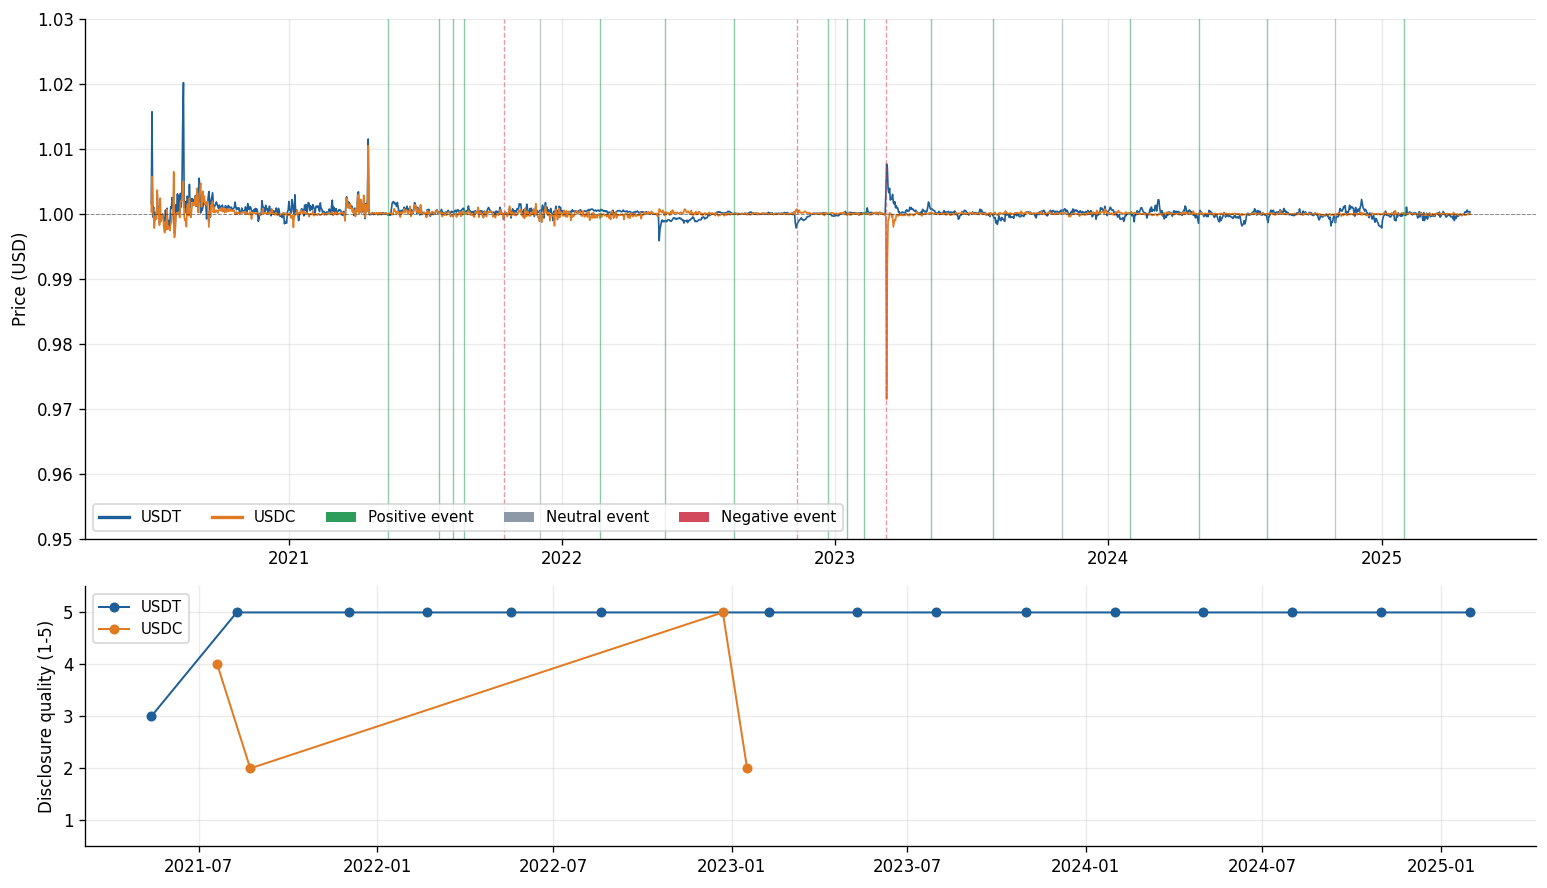

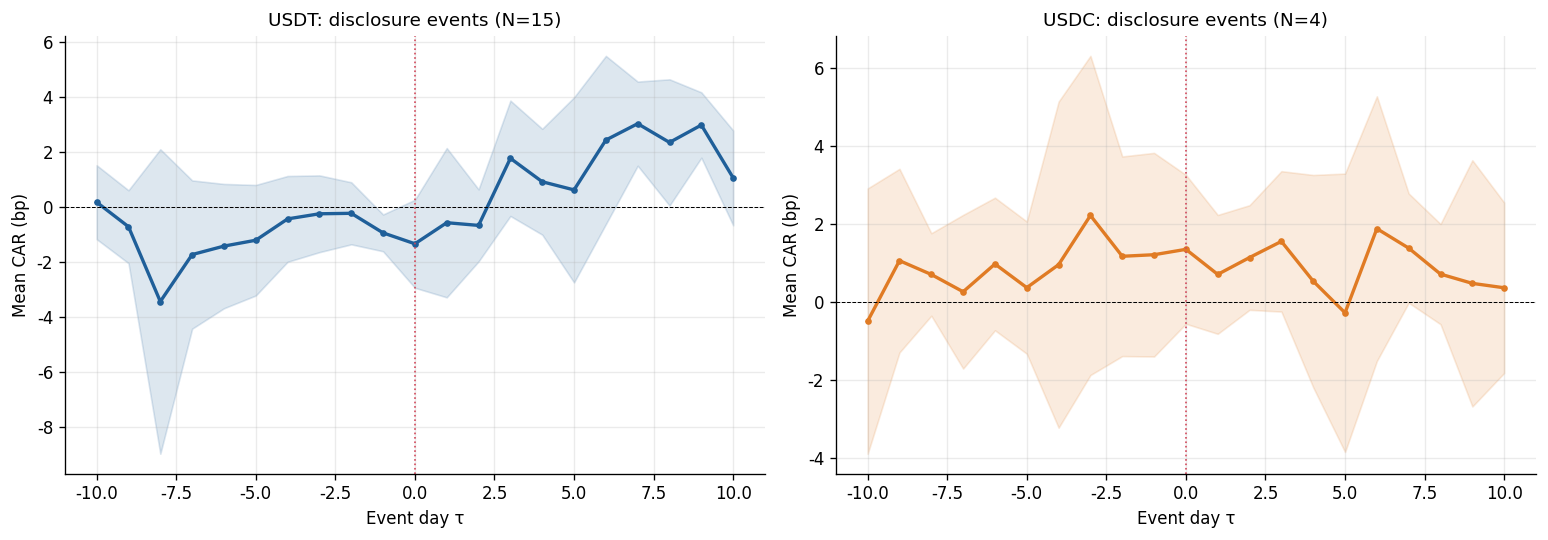

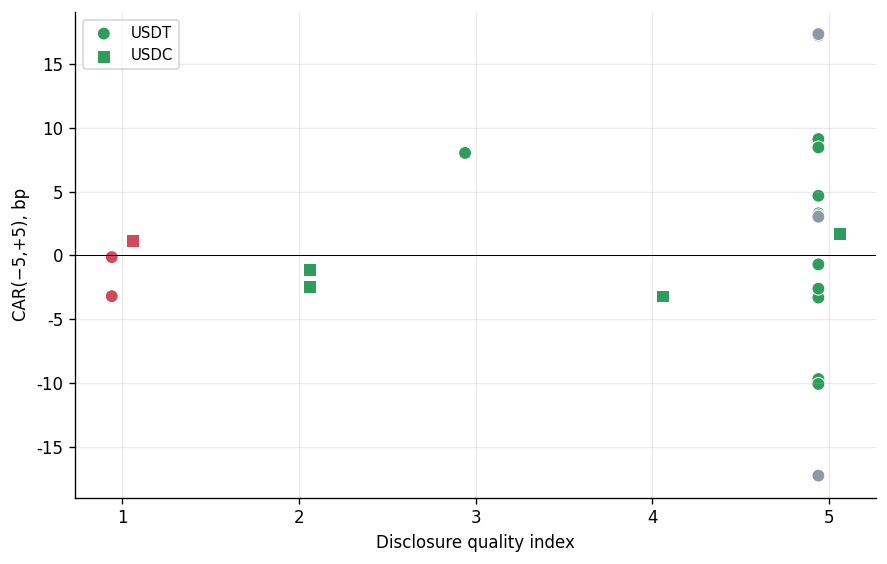

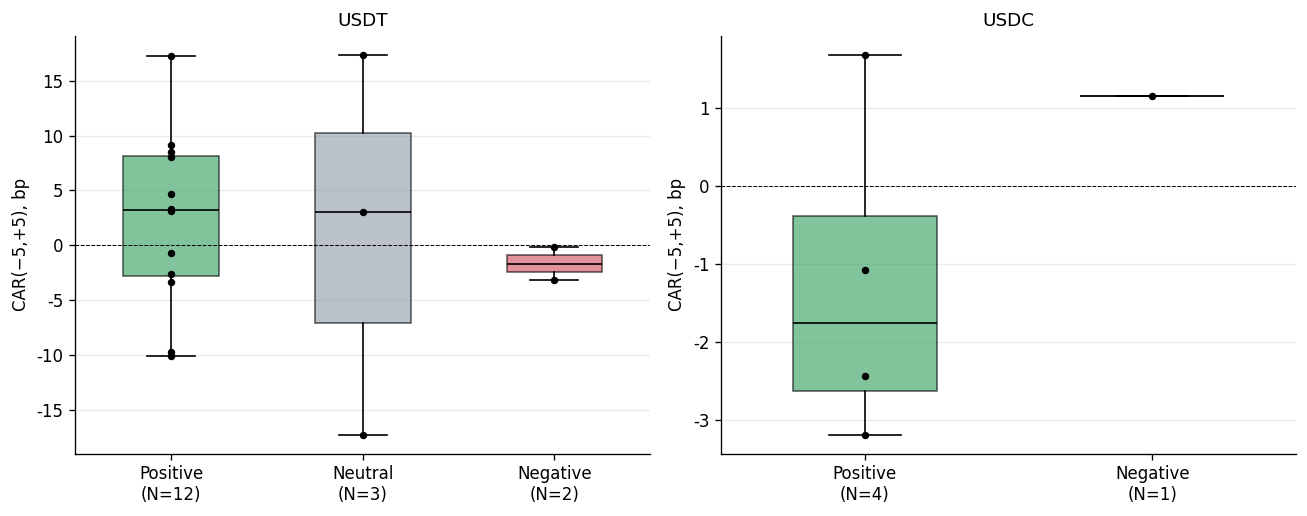

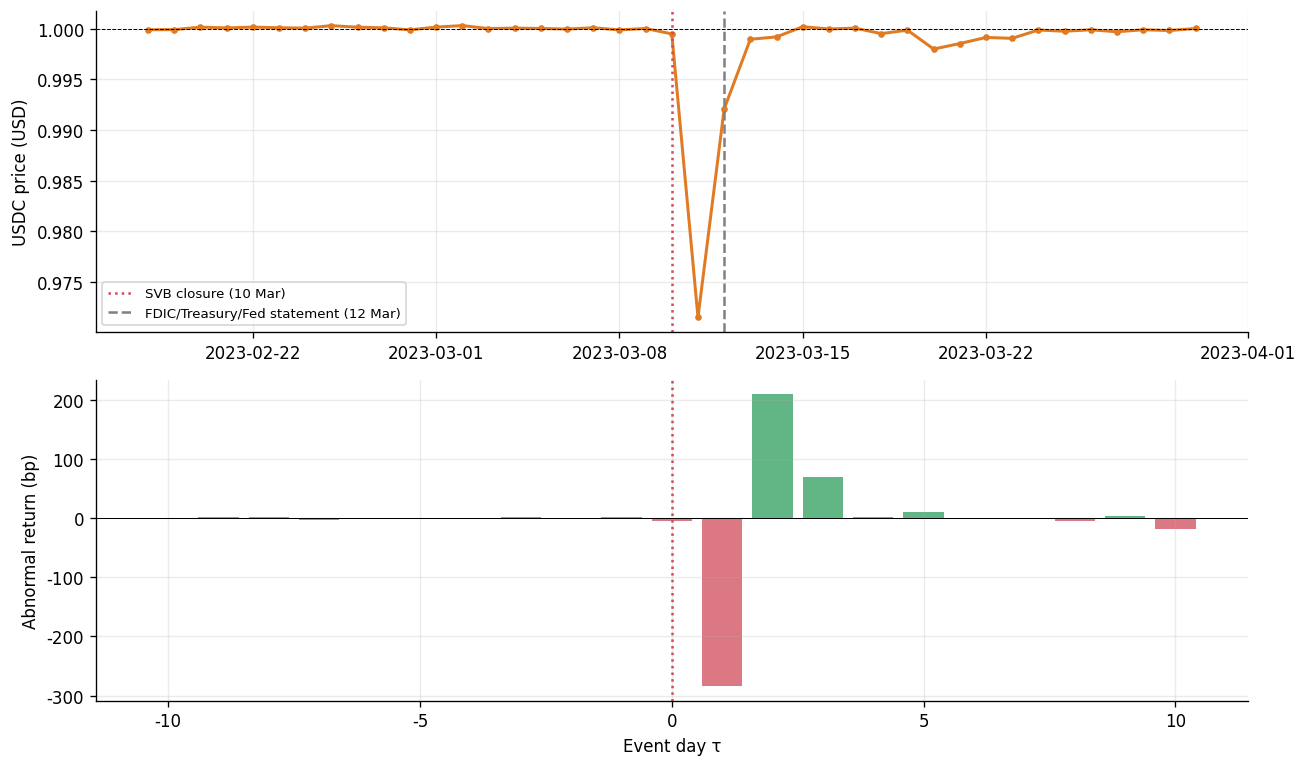

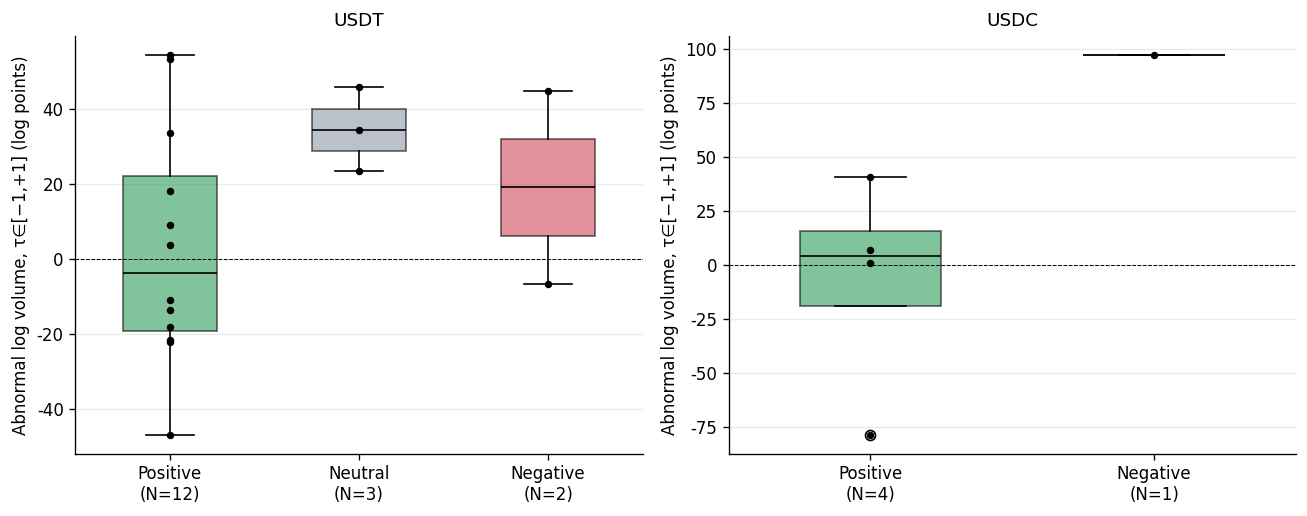

✅ Figures 1–6 saved


In [15]:
import matplotlib as _mpl
plt.rcParams.update({'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False})
_BOX_LABEL_KW = 'tick_labels' if tuple(int(x) for x in _mpl.__version__.split('.')[:2]) >= (3, 9) else 'labels'
palette = {'positive':'#2e9d5b','negative':'#d1495b','neutral':'#8d99a6'}
TYPE_EN = {'positive':'Positive','neutral':'Neutral','negative':'Negative'}
FIG = DIRS['figures']; DPI = 300

# Figure 1: prices, events, disclosure quality
fig, axes = plt.subplots(2,1,figsize=(13,7.5),gridspec_kw={'height_ratios':[2,1]})
ax = axes[0]
ax.plot(master['date'],master['p_usdt'],lw=1.0,color='#1f5f99',label='USDT')
ax.plot(master['date'],master['p_usdc'],lw=1.0,color='#e07b24',label='USDC')
ax.axhline(1.0,color='black',lw=0.6,ls='--',alpha=0.4)
for _,ev in events_df.iterrows():
    ax.axvline(ev['event_date'],color=palette[ev['event_type']],lw=0.8,alpha=0.55,
               ls='--' if ev['event_type']=='negative' else '-')
ax.legend(handles=[plt.Line2D([0],[0],color='#1f5f99',lw=2,label='USDT'),
                   plt.Line2D([0],[0],color='#e07b24',lw=2,label='USDC')]+
          [Patch(facecolor=palette[k],label=f'{TYPE_EN[k]} event') for k in ['positive','neutral','negative']],
          fontsize=9,ncol=5,loc='lower left')
ax.set_ylabel('Price (USD)'); ax.set_ylim(0.95,1.03); ax.grid(alpha=0.25)
ax2 = axes[1]
for coin,color in [('USDT','#1f5f99'),('USDC','#e07b24')]:
    s_ = events_df[(events_df['coin']==coin)&(events_df['event_type']!='negative')].sort_values('event_date')
    ax2.plot(s_['event_date'],s_['quality_score'],'o-',color=color,lw=1.2,ms=5,label=coin)
ax2.set_ylabel('Disclosure quality (1-5)'); ax2.set_ylim(0.5,5.5); ax2.legend(fontsize=9); ax2.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(f"{FIG}/Figure1_prices_events.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 2: average CAR path (excluding negative events)
fig,axes = plt.subplots(1,2,figsize=(13,4.6))
for ax,(cdf,coin,color) in zip(axes,[(car_usdt,'USDT','#1f5f99'),(car_usdc,'USDC','#e07b24')]):
    d_ = cdf[cdf['event_type']!='negative']
    s_ = tau_summary(d_, coin)
    ax.fill_between(s_['tau'],(s_['mean_CAR']-1.96*s_['se'])*1e4,(s_['mean_CAR']+1.96*s_['se'])*1e4,alpha=0.15,color=color)
    ax.plot(s_['tau'],s_['mean_CAR']*1e4,color=color,lw=2,marker='o',ms=3)
    ax.axhline(0,color='black',lw=0.6,ls='--'); ax.axvline(0,color='#d1495b',lw=1,ls=':')
    ax.set_title(f'{coin}: disclosure events (N={d_["event_date"].nunique()})',fontsize=11)
    ax.set_xlabel('Event day τ'); ax.set_ylabel('Mean CAR (bp)'); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(f"{FIG}/Figure2_car_path.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 3: quality vs CAR(-5,+5)
fig,ax = plt.subplots(figsize=(7.5,4.8))
for coin,mk in [('USDT','o'),('USDC','s')]:
    d_ = ev_all[ev_all['coin']==coin]
    ax.scatter(d_['quality_score']+(0.06 if coin=='USDC' else -0.06),d_[PRIMARY_WIN]*1e4,
               c=d_['event_type'].map(palette),marker=mk,s=60,edgecolors='white',lw=0.6,label=coin)
ax.axhline(0,color='black',lw=0.6)
ax.set_xlabel('Disclosure quality index'); ax.set_ylabel('CAR(−5,+5), bp'); ax.set_xticks([1,2,3,4,5])
ax.legend(fontsize=9); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(f"{FIG}/Figure3_quality_car.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 4: CAR(-5,+5) by event type
fig,axes = plt.subplots(1,2,figsize=(11,4.4))
for ax,coin in zip(axes,['USDT','USDC']):
    d_ = ev_all[ev_all['coin']==coin]
    order = [t for t in ['positive','neutral','negative'] if t in d_['event_type'].values]
    data = [d_[d_['event_type']==t][PRIMARY_WIN].values*1e4 for t in order]
    bp_ = ax.boxplot(data,**{_BOX_LABEL_KW:[f'{TYPE_EN[t]}\n(N={len(x)})' for t,x in zip(order,data)]},
                     patch_artist=True,widths=0.5,medianprops=dict(color='black'))
    for patch,t in zip(bp_['boxes'],order): patch.set(facecolor=palette[t],alpha=0.6)
    for k,(t,x) in enumerate(zip(order,data)):
        ax.scatter(np.full(len(x),k+1),x,color='black',s=12,zorder=3)
    ax.axhline(0,color='black',lw=0.6,ls='--'); ax.set_title(coin,fontsize=11); ax.set_ylabel('CAR(−5,+5), bp'); ax.grid(alpha=0.25,axis='y')
plt.tight_layout(); plt.savefig(f"{FIG}/Figure4_car_by_type.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 5: SVB case
svb = pd.Timestamp('2023-03-10')
w5  = master[(master['date']>=svb-pd.Timedelta('20d'))&(master['date']<=svb+pd.Timedelta('20d'))]
fig,(a1,a2) = plt.subplots(2,1,figsize=(11,6.5))
a1.plot(w5['date'],w5['p_usdc'],color='#e07b24',lw=1.8,marker='o',ms=3)
a1.axhline(1.0,color='black',lw=0.6,ls='--'); a1.axvline(svb,color='#d1495b',ls=':',label='SVB closure (10 Mar)')
a1.axvline(pd.Timestamp('2023-03-12'),color='gray',ls='--',label='FDIC/Treasury/Fed statement (12 Mar)')
a1.set_ylabel('USDC price (USD)'); a1.legend(fontsize=8); a1.grid(alpha=0.25)
sc = car_usdc[car_usdc['event_date']==svb].sort_values('tau')
a2.bar(sc['tau'],sc['AR']*1e4,color=np.where(sc['AR']<0,'#d1495b','#2e9d5b'),alpha=0.75)
a2.axhline(0,color='black',lw=0.6); a2.axvline(0,color='#d1495b',ls=':')
a2.set_xlabel('Event day τ'); a2.set_ylabel('Abnormal return (bp)'); a2.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(f"{FIG}/Figure5_svb.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 6: abnormal trading volume by event type
av_ = pd.read_csv(f"{DIRS['results']}/abnormal_volume.csv")
fig,axes = plt.subplots(1,2,figsize=(11,4.4))
for ax,coin in zip(axes,['USDT','USDC']):
    d_ = av_[av_['coin']==coin]
    order = [t for t in ['positive','neutral','negative'] if t in d_['event_type'].values]
    data = [d_[d_['event_type']==t]['AV_-1_1'].values for t in order]
    bp_ = ax.boxplot(data,**{_BOX_LABEL_KW:[f'{TYPE_EN[t]}\n(N={len(x)})' for t,x in zip(order,data)]},
                     patch_artist=True,widths=0.5,medianprops=dict(color='black'))
    for patch,t in zip(bp_['boxes'],order): patch.set(facecolor=palette[t],alpha=0.6)
    for k,x in enumerate(data): ax.scatter(np.full(len(x),k+1),x,color='black',s=12,zorder=3)
    ax.axhline(0,color='black',lw=0.6,ls='--'); ax.set_title(coin,fontsize=11)
    ax.set_ylabel('Abnormal log volume, τ∈[−1,+1] (log points)'); ax.grid(alpha=0.25,axis='y')
plt.tight_layout(); plt.savefig(f"{FIG}/Figure6_volume.png",dpi=DPI,bbox_inches='tight'); plt.show()
print('✅ Figures 1–6 saved')


---
## STEP 13 | 테이블 & 최종 요약

> Table 2 (이벤트별 CAR) 생성. H1·H2·H3 결과 집약 출력.


In [16]:
# Table 2
t2 = ev_all[['coin','event_date','event_type','quality_score',
              'CAR_-1_1','CAR_-3_3','CAR_-5_5']].copy()
t2['event_date'] = t2['event_date'].dt.strftime('%Y-%m-%d')
for c in ['CAR_-1_1','CAR_-3_3','CAR_-5_5']:
    t2[c] = (t2[c] * 10000).round(3)
t2.columns = ['코인','공시일','유형','품질지수',
               'CAR(-1,+1)bp','CAR(-3,+3)bp','CAR(-5,+5)bp']
t2.to_csv(f"{DIRS['tables']}/Table2_event_CAR.csv",
          index=False, encoding='utf-8-sig')
print(f'Table 2: {len(t2)}건  ✅')

print('\n'+'='*70)
print('📋 최종 분석 결과 요약 (v9: 공개일 기준 이벤트)')
print('='*70)
print(f'  기간: {master.date.min().date()} ~ {master.date.max().date()} ({len(master)}일)')
print(f'  이벤트: USDT {len(ev_usdt)}건 / USDC {len(ev_usdc)}건 = {len(ev_all)}건')
print(f'  주 창: {PRIMARY_WIN}  (잔차 정규성 통과)')
print()

h1k = pd.read_csv(f"{DIRS['results']}/H1_results.csv")
print('[H1]:')
for _,r in h1k[h1k['window']==PRIMARY_WIN].iterrows():
    sig = ('***' if r['p']<0.01 else '**' if r['p']<0.05
           else '*' if r['p']<0.1 else 'n.s.')
    cnfl = '  ⚠ Boot·t 불일치' if r.get('conflict',False) else ''
    print(f'  {r["coin"]:4s}  mean={r["mean_bp"]:+8.3f}bp  '
          f't={r["t"]:6.3f}  p={r["p"]:.4f} {sig}  '
          f'Boot95%=[{r["boot_lo_bp"]:+.3f},{r["boot_hi_bp"]:+.3f}]{cnfl}')

h2k = pd.read_csv(f"{DIRS['results']}/H2_regression.csv")
pw  = h2k[(h2k['var']=='quality_score')&(h2k['window']==PRIMARY_WIN)].iloc[0]
dg  = pd.read_csv(f"{DIRS['results']}/H2_residual_diagnostics.csv")
dw_row = dg[dg['window']==PRIMARY_WIN].iloc[0]
adj = dw_row['AdjR2']
adj_note = '  ⚠ 음수' if adj < 0 else ''
print(f'\n[H2] {PRIMARY_WIN}: '
      f'coef={pw.coef_bp:.4f}bp  p={pw.p:.4f}  '
      f'R²={dw_row["R2"]:.4f}  Adj-R²={adj:.4f}{adj_note}  '
      f'VIF_max={dw_row["VIF_max"]:.3f}  SE={pw.se_type}  WCR boot p={pw.p_wcr_boot:.4f}')

h3k = pd.read_csv(f"{DIRS['results']}/H3_results.csv")
print(f'\n[H3] {PRIMARY_WIN}:')
for _,r in h3k[h3k['window']==PRIMARY_WIN].iterrows():
    rn = r['ratio_note'] if pd.notna(r.get('ratio_note','')) else ''
    rv = f'{r["ratio"]:.2f}x ({rn})' if pd.notna(r['ratio']) else rn
    if r['test_feasible']:
        sig = ('***' if r['p_ttest']<0.01 else '**' if r['p_ttest']<0.05
               else '*' if r['p_ttest']<0.1 else 'n.s.')
        print(f'  {r["coin"]:4s}  긍정={r["pos_mean_bp"]:+8.3f}bp  '
              f'부정={r["neg_mean_bp"]:+8.3f}bp  비율={rv}  '
              f'p={r["p_ttest"]:.4f}{sig}  [{r["direction"]}]')
    else:
        print(f'  {r["coin"]:4s}  검정불가(N_neg={r["n_neg"]})  '
              f'부정={r["neg_mean_bp"]:+8.3f}bp  비율={rv}  [{r["direction"]}]')

print()



Table 2: 22건  ✅

📋 최종 분석 결과 요약 (v9: 공개일 기준 이벤트)
  기간: 2020-07-01 ~ 2025-04-29 (1764일)
  이벤트: USDT 17건 / USDC 5건 = 22건
  주 창: CAR_-5_5  (잔차 정규성 통과)

[H1]:
  USDT  mean=  +1.606bp  t= 0.722  p=0.4807 n.s.  Boot95%=[-2.565,+5.940]
  USDC  mean=  -0.771bp  t=-0.804  p=0.4662 n.s.  Boot95%=[-2.460,+0.918]

[H2] CAR_-5_5: coef=-0.1333bp  p=0.9204  R²=0.0219  Adj-R²=-0.1411  ⚠ 음수  VIF_max=4.274  SE=Cluster(date, G=22)  WCR boot p=0.9497

[H3] CAR_-5_5:
  USDT  긍정=  +2.294bp  부정=  -1.668bp  비율=0.73x (H3 방향 일치)  p=0.1950n.s.  [음수 — H3 방향 일치]
  USDC  검정불가(N_neg=1)  부정=  +1.151bp  비율=0.92x (H3 방향 일치)  [N_neg=1: 방향 해석 불가(단일 사례)]

